# 04 · Aprendizaje no supervisado

En este notebook agrupamos las reservas para encontrar perfiles de comportamiento, sin usar la cancelación. Empezamos por K-Means.

## 1. Qué buscamos con el agrupamiento

### 1.1 El problema

El componente supervisado le pone a cada reserva un riesgo de cancelación. El no supervisado responde otra pregunta: **qué tipos de reservas recibe el hotel**. Si las reservas se pueden repartir en unos pocos perfiles con sentido (por ejemplo, escapadas de fin de semana, viajes de familia o reservas de último minuto), el hotel puede manejar cada perfil con una política distinta en vez de tratar todas las reservas igual. Es la tercera pregunta del notebook 01, y la base para la cuarta: cómo se relacionan esos perfiles con las cancelaciones.

**Por qué `is_canceled` no entra.** El enunciado lo prohíbe, y además tiene sentido. Si la cancelación entrara al agrupamiento, los grupos se armarían para separar canceladas de no canceladas, y eso sería un modelo supervisado disfrazado. Lo que queremos es lo contrario: encontrar los perfiles solo con cómo es la reserva y, ya con los grupos armados, mirar en la sección 4 cuánto cancela cada uno. Si ahí aparecen diferencias, son una evidencia más honesta de que los perfiles tienen que ver con la cancelación, porque nadie los obligó a separarla.

### 1.2 Los datos

Usamos el entrenamiento que dejó el notebook 02 en `data/processed/`, con la misma limpieza: sin filas imposibles y sin duplicados sobre las columnas del modelo. Todo lo que aprende de los datos (el escalado y el agrupamiento) se ajusta solo con estas reservas. La prueba no la usamos aquí; queda disponible por si se necesita comprobar que los segmentos se sostienen con reservas que el agrupamiento no vio, porque K-Means puede asignarle un grupo a una reserva nueva.

### 1.3 Las variables para segmentar

El enunciado pide analizar los segmentos según la anticipación, la duración de la estancia, el tipo de cliente, el canal de distribución y las características de la reserva. Con eso escogimos siete variables, todas conocidas al momento de reservar:

| Dimensión del enunciado | Variable | Qué mide |
|---|---|---|
| Anticipación | `lead_time` | Días entre la reserva y la llegada |
| Duración de la estancia | `total_noches` | Noches de la reserva |
| | `proporcion_fin_semana` | Parte de esas noches que cae en sábado o domingo. La calculamos aquí: 1 es una estancia solo de fin de semana y 0 una solo entre semana |
| Características de la reserva | `total_huespedes` | Adultos, niños y bebés |
| | `con_menores` | 1 si viajan niños o bebés. También la calculamos aquí |
| Tipo de cliente | `customer_type` | *Transient*, *Transient-Party*, *Contract* o *Group* |
| Canal de distribución | `distribution_channel` | *TA/TO*, *Direct*, *Corporate* y los canales raros |

Y dejamos por fuera, con estas razones:

- **`adr`, `total_of_special_requests` y `required_car_parking_spaces`.** El plan del equipo las incluía como características de la reserva, pero el notebook 01 (sección 3.8) y el notebook 02 mostraron que pueden llenarse o calcularse después de reservar, y no vienen en los datos procesados. El parqueadero, además, tiene 0 cancelaciones en 7.313 reservas: si un grupo se armara alrededor de él, saldría con una cancelación de casi cero por cómo se registra el dato y no por el perfil del cliente. Usar solo lo que se sabe al reservar tiene otra ventaja: el hotel puede ubicar una reserva en su segmento apenas entra.
- **`agent`.** Son cientos de códigos anonimizados. En el one-hot ocuparían más columnas que todo lo demás junto y los grupos terminarían siendo grupos de agencias. Tampoco está en la lista del enunciado.
- **`market_segment`.** Dice casi lo mismo que el canal (V de Cramér de 0,729, sección 2.2 del notebook 03), y el enunciado pide el canal.
- **`hotel` y `meal`.** No describen el comportamiento de la reserva sino dónde y con qué plan se hace. Las dejamos para describir los segmentos en la sección 4, donde sirve ver si un perfil se concentra en un hotel.
- **El historial del cliente** (`is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled`). Describe al cliente y no la reserva, y casi todos los clientes están en cero.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

sys.path.insert(0, str(Path("../src").resolve()))

from preprocesamiento import OBJETIVO, SEMILLA

RUTA_ENTRENAMIENTO = Path("../data/processed/entrenamiento.csv.gz")
VARIABLES_LOGARITMO = ["lead_time", "total_noches", "total_huespedes"]
VARIABLES_ESCALADAS = ["proporcion_fin_semana"]
VARIABLES_BINARIAS = ["con_menores"]
VARIABLES_CATEGORICAS = ["customer_type", "distribution_channel"]
VARIABLES_SEGMENTACION = VARIABLES_LOGARITMO + VARIABLES_ESCALADAS + VARIABLES_BINARIAS + VARIABLES_CATEGORICAS
FRECUENCIA_MINIMA_CATEGORIA = 0.01

VALORES_K = range(2, 11)
N_INICIOS = 10
MUESTRA_SILHOUETTE = 10_000
REPETICIONES_SILHOUETTE = 3

COLOR_PRINCIPAL = "#087F8C"
COLOR_SECUNDARIO = "#A0AEC0"
COLOR_RIESGO = "#916313"

sns.set_theme(style="whitegrid")

In [2]:
def variables_de_segmentacion(datos):
    """Selecciona las variables del agrupamiento y calcula las dos derivadas."""
    segmentacion = datos.assign(
        proporcion_fin_semana=datos["stays_in_weekend_nights"] / datos["total_noches"],
        con_menores=(datos["children"] + datos["babies"]).gt(0).astype(int),
    )
    return segmentacion[VARIABLES_SEGMENTACION]


entrenamiento = pd.read_csv(RUTA_ENTRENAMIENTO)
X_segmentacion = variables_de_segmentacion(entrenamiento)

assert OBJETIVO not in X_segmentacion.columns
assert entrenamiento["total_noches"].gt(0).all()
print(f"Reservas para agrupar: {len(X_segmentacion):,}")
print(f"Variables: {X_segmentacion.shape[1]} ({', '.join(X_segmentacion.columns)})")

Reservas para agrupar: 63,351
Variables: 7 (lead_time, total_noches, total_huespedes, proporcion_fin_semana, con_menores, customer_type, distribution_channel)


### 1.4 Preparación

K-Means agrupa por distancias, así que todas las variables tienen que estar en escalas comparables: si no, la anticipación, que va de 0 a cientos de días, mandaría sobre las demás. Pero estandarizar no basta cuando una variable tiene una cola muy larga, porque las pocas reservas extremas quedan muy lejos de todas y pueden armar un grupo solo para ellas. Por eso miramos primero la asimetría de las numéricas.

In [3]:
asimetria = pd.DataFrame({
    "asimetría original": X_segmentacion[VARIABLES_LOGARITMO + VARIABLES_ESCALADAS].skew(),
    "asimetría con logaritmo": np.log1p(X_segmentacion[VARIABLES_LOGARITMO]).skew(),
})
display(asimetria.round(2))
X_segmentacion[VARIABLES_LOGARITMO].describe().round(1)

,asimetría original,asimetría con logaritmo
lead_time,1.42,-0.71
proporcion_fin_semana,1.04,NaN
total_huespedes,12.42,0.19
total_noches,3.11,0.32


,lead_time,total_noches,total_huespedes
count,63351.0,63351.0,63351.0
mean,77.4,3.7,2.1
std,82.9,2.8,0.8
min,0.0,1.0,1.0
25%,11.0,2.0,2.0
50%,48.0,3.0,2.0
75%,121.0,5.0,2.0
max,709.0,69.0,55.0


**¿Qué vemos?** Las tres variables de conteo tienen colas largas: hay reservas con 709 días de anticipación, 69 noches o 55 huéspedes, cuando la mediana es de 2 huéspedes. `total_huespedes` es la más asimétrica (12,42). Con el logaritmo de 1 más el valor, la asimetría de las tres queda por debajo de 1 en valor absoluto, y las reservas extremas siguen siendo las más grandes, pero ya no quedan tan lejos de las demás. `proporcion_fin_semana` va de 0 a 1 y no la transformamos.

La preparación queda así, dentro de un `ColumnTransformer` que se ajusta con el entrenamiento:

- `lead_time`, `total_noches` y `total_huespedes`: logaritmo de 1 más el valor y después estandarización.
- `proporcion_fin_semana`: estandarización.
- `con_menores`: queda en 0 y 1, sin estandarizar. Si la estandarizáramos, como solo una parte pequeña de las reservas tiene menores, ese 1 se convertiría en un valor muy grande y pesaría más que cualquier otra variable.
- `customer_type` y `distribution_channel`: one-hot en 0 y 1, por la misma razón sin estandarizar. Las categorías con menos del 1 % de las reservas se juntan en una sola columna.

In [4]:
def crear_preparador():
    """Transformador sin ajustar para las variables de segmentación."""
    return ColumnTransformer([
        ("logaritmo", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                    StandardScaler()), VARIABLES_LOGARITMO),
        ("escaladas", StandardScaler(), VARIABLES_ESCALADAS),
        ("binarias", "passthrough", VARIABLES_BINARIAS),
        ("categoricas", OneHotEncoder(min_frequency=FRECUENCIA_MINIMA_CATEGORIA,
                                      handle_unknown="infrequent_if_exist", sparse_output=False),
         VARIABLES_CATEGORICAS),
    ])


preparador = crear_preparador()
Z_entrenamiento = preparador.fit_transform(X_segmentacion)
columnas_z = (
    pd.Series(preparador.get_feature_names_out())
    .str.replace(r"^[a-z]+__", "", regex=True)
    .str.replace("infrequent_sklearn", "otros")
)

varianza_por_variable = (
    pd.Series(Z_entrenamiento.var(axis=0), index=columnas_z)
    .groupby(lambda columna: next(v for v in VARIABLES_SEGMENTACION if columna.startswith(v)))
    .sum()
    .reindex(VARIABLES_SEGMENTACION)
)
print(f"Matriz para K-Means: {Z_entrenamiento.shape[0]:,} filas y {Z_entrenamiento.shape[1]} columnas")
varianza_por_variable.round(3).to_frame("varianza total de sus columnas")

Matriz para K-Means: 63,351 filas y 13 columnas


,varianza total de sus columnas
lead_time,1.000
total_noches,1.000
total_huespedes,1.000
proporcion_fin_semana,1.000
con_menores,0.100
customer_type,0.247
distribution_channel,0.342


**¿Qué vemos?** Cada variable numérica aporta una varianza de 1 por estar estandarizada, mientras que `con_menores`, el tipo de cliente y el canal aportan bastante menos (0,100, 0,247 y 0,342), porque en 0 y 1 su varianza depende de qué tan repartidas estén sus categorías. Y casi todas las reservas son *Transient* o llegan por *TA/TO*. Para K-Means, que busca grupos donde la distancia al centro sea pequeña, eso quiere decir que el tipo de cliente y el canal van a pesar menos que la anticipación o las noches. Lo dejamos así a propósito: si las estandarizáramos, una categoría con pocas reservas, como *Contract*, quedaría con valores muy grandes y podría armar un grupo solo para ella, igual que con `con_menores`. Al leer los grupos hay que tenerlo presente.

## 2. K-Means

### 2.1 Por qué K-Means

**Cómo funciona.** Se escoge un número de grupos *k* y K-Means ubica *k* centros. Asigna cada reserva al centro más cercano (con distancia euclidiana), mueve cada centro al promedio de las reservas que le quedaron y repite hasta que las asignaciones dejan de cambiar. Lo que minimiza es la **inercia**: la suma de las distancias al cuadrado de cada reserva a su centro.

Lo escogimos como primer algoritmo porque:

- **Da lo que el hotel puede usar**: pocos segmentos, cada reserva en uno solo, y un centro que funciona como "la reserva típica" del segmento.
- **Es rápido** con las 63.351 reservas completas, sin tener que sacar una muestra. El agrupamiento jerárquico de la sección 3 no puede trabajar con todas.
- **Asigna reservas nuevas** con el mismo modelo: basta medir a qué centro quedan más cerca.

Sus supuestos:

- **Grupos más o menos esféricos y de tamaño y dispersión parecidos**, porque cada reserva va al centro más cercano sin importar la forma del grupo.
- **Que la distancia euclidiana tenga sentido**, o sea, variables en escalas comparables. Por eso la preparación de la 1.4.
- **Que exista un *k* razonable**: el algoritmo no lo escoge, se lo damos nosotros.

Sus limitaciones frente a estos datos:

- **Siempre encuentra *k* grupos**, aunque los datos no tengan grupos naturales. Por eso hay que medir qué tan separados quedan.
- **Es sensible a los atípicos**, porque el centro es un promedio. El logaritmo de la 1.4 reduce el problema, pero no lo elimina.
- **Depende del punto de partida.** Lo corremos con `N_INICIOS` = 10 puntos de partida distintos y se queda con el de menor inercia.
- **La distancia euclidiana es una aproximación para las categóricas.** Existen variantes pensadas para datos mixtos, como K-Prototypes, pero no están en scikit-learn ni en el curso; con el one-hot en 0 y 1 la aproximación es razonable.

### 2.2 Cuántos grupos

Corremos K-Means con *k* de 2 a 10 y calculamos cuatro medidas:

- **Inercia (método del codo).** Siempre baja al aumentar *k*; buscamos el punto desde el que agregar grupos ya casi no la reduce.
- **Silhouette.** Para cada reserva compara la distancia promedio a su propio grupo (*a*) con la del grupo vecino más cercano (*b*): (*b* − *a*) / máx(*a*, *b*). Va de −1 a 1 y más alto es mejor. Una referencia común (Kaufman y Rousseeuw) es que por encima de 0,5 hay una estructura razonable, entre 0,26 y 0,5 la estructura es débil y por debajo de 0,25 no hay una estructura sustancial. Calcularlo con todas las reservas exige comparar cada una con todas las demás, unos 4.000 millones de distancias, así que lo calculamos sobre muestras aleatorias de 10.000 reservas, repetido tres veces con semillas distintas para ver cuánto cambia.
- **Davies-Bouldin.** Para cada grupo busca el grupo más parecido y compara la dispersión de los dos con la distancia entre sus centros. Más bajo es mejor; 0 sería grupos perfectamente separados.
- **Calinski-Harabasz.** Divide la dispersión entre grupos por la dispersión dentro de los grupos, ajustando por *k* y por el número de reservas. Más alto es mejor.

In [5]:
def evaluar_agrupamiento(Z, etiquetas):
    """Silhouette (media y desviación en muestras), Davies-Bouldin y Calinski-Harabasz de un agrupamiento."""
    silhouettes = [
        silhouette_score(Z, etiquetas, sample_size=min(MUESTRA_SILHOUETTE, len(Z)), random_state=SEMILLA + repeticion)
        for repeticion in range(REPETICIONES_SILHOUETTE)
    ]
    return {
        "Silhouette": np.mean(silhouettes),
        "Silhouette (desviación)": np.std(silhouettes),
        "Davies-Bouldin": davies_bouldin_score(Z, etiquetas),
        "Calinski-Harabasz": calinski_harabasz_score(Z, etiquetas),
    }


def crear_kmeans(k):
    """K-Means con varios puntos de partida y la semilla del equipo."""
    return KMeans(n_clusters=k, n_init=N_INICIOS, random_state=SEMILLA)


filas = []
modelos_kmeans = {}
for k in VALORES_K:
    modelos_kmeans[k] = crear_kmeans(k).fit(Z_entrenamiento)
    etiquetas = modelos_kmeans[k].labels_
    filas.append({
        "k": k,
        "inercia": modelos_kmeans[k].inertia_,
        **evaluar_agrupamiento(Z_entrenamiento, etiquetas),
        "grupo más pequeño": np.bincount(etiquetas).min(),
    })
metricas_por_k = pd.DataFrame(filas).set_index("k")
metricas_por_k["reducción de inercia (%)"] = -metricas_por_k["inercia"].pct_change() * 100
metricas_por_k.round(3)

,inercia,Silhouette,Silhouette (desviación),Davies-Bouldin,Calinski-Harabasz,grupo más pequeño,reducción de inercia (%)
k,,,,,,,
2,224691.055,0.270,0.001,1.609,20407.242,21038,NaN
3,186829.667,0.266,0.002,1.350,18690.038,9753,16.850
4,162834.483,0.249,0.001,1.392,17407.471,8497,12.843
5,143998.435,0.234,0.002,1.341,16834.659,7366,11.568
6,131710.526,0.241,0.002,1.341,15905.936,6480,8.533
7,119877.858,0.232,0.002,1.368,15605.139,4240,8.984
8,111726.537,0.240,0.002,1.298,15011.659,4208,6.800
9,107567.119,0.244,0.001,1.268,13949.057,2918,3.723
10,101147.633,0.242,0.002,1.332,13632.601,3258,5.968


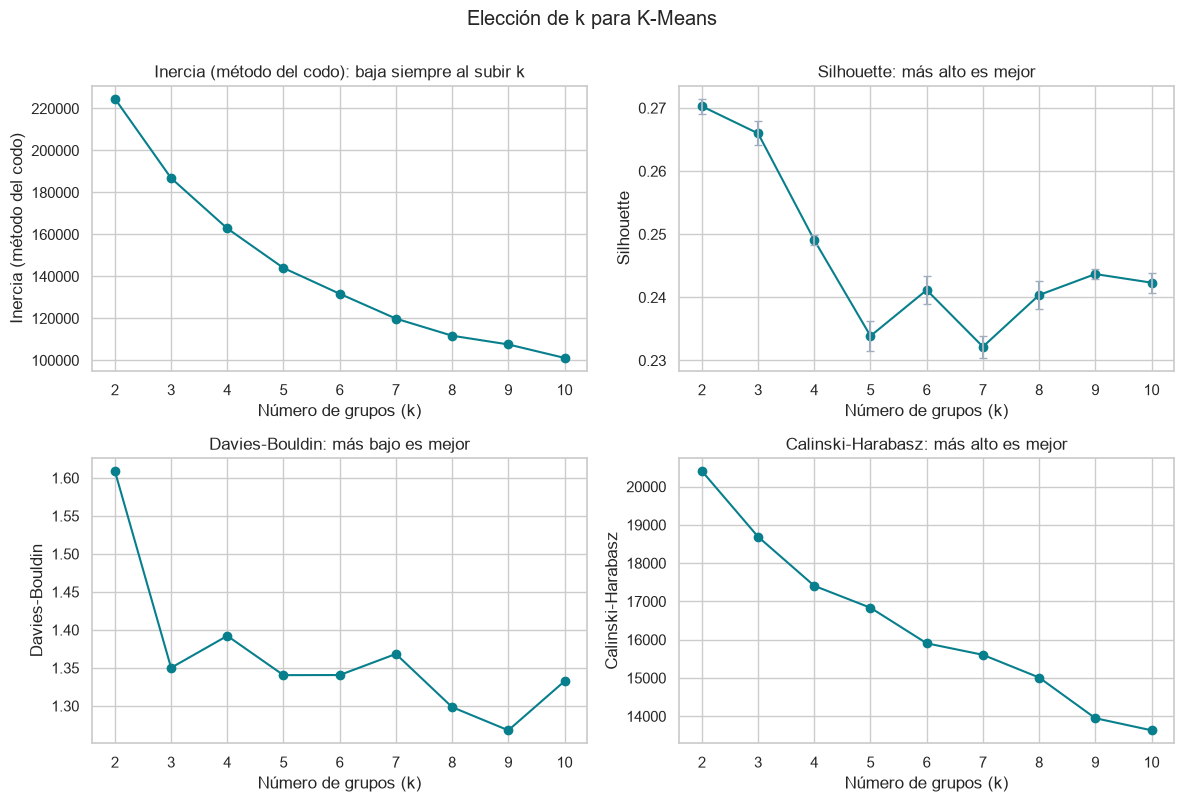

In [6]:
paneles = [
    ("inercia", "Inercia (método del codo)", "baja siempre al subir k"),
    ("Silhouette", "Silhouette", "más alto es mejor"),
    ("Davies-Bouldin", "Davies-Bouldin", "más bajo es mejor"),
    ("Calinski-Harabasz", "Calinski-Harabasz", "más alto es mejor"),
]
fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (columna, titulo, lectura) in zip(ejes.flat, paneles):
    ax.plot(metricas_por_k.index, metricas_por_k[columna], marker="o", color=COLOR_PRINCIPAL)
    if columna == "Silhouette":
        ax.errorbar(metricas_por_k.index, metricas_por_k[columna],
                    yerr=metricas_por_k["Silhouette (desviación)"], fmt="none", color=COLOR_SECUNDARIO, capsize=3)
    ax.set_title(f"{titulo}: {lectura}")
    ax.set_xlabel("Número de grupos (k)")
    ax.set_ylabel(titulo)
    ax.set_xticks(list(VALORES_K))
plt.suptitle("Elección de k para K-Means", y=1.0)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **No hay un codo claro.** La inercia baja 16,9 % de 2 a 3 grupos y 12,8 % de 3 a 4, y de ahí en adelante sigue bajando poco a poco (entre 3,7 % y 11,6 % por cada grupo más). No hay un punto donde la curva se doble de golpe.
- **El Silhouette es bajo para cualquier *k***: va de 0,270 con *k* = 2 a 0,232 con *k* = 7, en el borde entre "estructura débil" y "sin estructura sustancial". Las tres muestras dan casi lo mismo (desviación de 0,002 o menos), así que no es un problema de la muestra. Las reservas no forman grupos naturales bien separados: se parecen más a un continuo, que los segmentos parten en pedazos.
- **Las otras dos medidas tampoco coinciden.** Calinski-Harabasz es máximo con *k* = 2 y baja siempre. Davies-Bouldin mejora mucho de 2 a 3 grupos (de 1,609 a 1,350) y después queda entre 1,268 y 1,392 sin una tendencia clara.

Con medidas tan parejas, ninguna escoge *k* por sí sola. Los candidatos razonables son *k* = 3, que tiene casi el mismo Silhouette que *k* = 2 y un Davies-Bouldin mucho mejor, y *k* = 4, que es el siguiente en Silhouette. Para decidir entre esos dos miramos qué describen los centros, solo con las variables del agrupamiento.

In [7]:
def describir_centros(etiquetas):
    """Valores típicos de cada grupo en las unidades originales de las variables de segmentación."""
    datos = X_segmentacion.assign(grupo=etiquetas)
    descripcion = datos.groupby("grupo").agg(
        reservas=("lead_time", "size"),
        anticipacion_mediana=("lead_time", "median"),
        noches_mediana=("total_noches", "median"),
        fin_de_semana=("proporcion_fin_semana", "mean"),
        huespedes_promedio=("total_huespedes", "mean"),
        con_menores=("con_menores", "mean"),
        transient=("customer_type", lambda tipo: tipo.eq("Transient").mean()),
        canal_ta_to=("distribution_channel", lambda canal: canal.eq("TA/TO").mean()),
        canal_directo_o_corporativo=("distribution_channel", lambda canal: canal.isin(["Direct", "Corporate"]).mean()),
    )
    proporciones = ["fin_de_semana", "con_menores", "transient", "canal_ta_to", "canal_directo_o_corporativo"]
    descripcion[proporciones] = descripcion[proporciones] * 100
    return descripcion.rename(columns={columna: f"{columna} (%)" for columna in proporciones})


for k in (3, 4):
    print(f"k = {k}")
    display(describir_centros(modelos_kmeans[k].labels_).round(1))

k = 3


,reservas,anticipacion_mediana,noches_mediana,fin_de_semana (%),huespedes_promedio,con_menores (%),transient (%),canal_ta_to (%),canal_directo_o_corporativo (%)
grupo,,,,,,,,,
0,35479,98.0,4.0,25.7,2.3,15.6,86.1,88.5,11.5
1,9753,17.0,2.0,75.1,1.9,6.4,87.2,75.1,24.4
2,18119,8.0,1.0,2.4,1.7,5.4,85.7,64.4,35.2


k = 4


,reservas,anticipacion_mediana,noches_mediana,fin_de_semana (%),huespedes_promedio,con_menores (%),transient (%),canal_ta_to (%),canal_directo_o_corporativo (%)
grupo,,,,,,,,,
0,8497,14.0,2.0,77.7,1.8,4.2,87.9,73.0,26.5
1,28852,97.0,4.0,26.1,1.9,0.9,83.8,89.5,10.5
2,16156,6.0,1.0,2.1,1.7,2.3,85.9,62.2,37.3
3,9846,77.0,4.0,24.5,3.4,62.3,91.8,84.5,15.4


**¿Qué vemos?**

- Con *k* = 3, K-Means separa las reservas por anticipación y por si la estancia cae en fin de semana: un grupo grande de reservas hechas con meses de anticipación, uno de estancias de fin de semana con poca anticipación y uno de reservas de una noche entre semana con muy poca anticipación. Las reservas con menores quedan repartidas, con 15,6 % en el grupo de anticipadas.
- Con *k* = 4 se mantienen esos tres perfiles y aparece uno nuevo: **viajes con menores**, con 62,3 % de reservas con niños o bebés y 3,4 huéspedes en promedio, contra menos de 2 en los demás. Ese grupo sale de las reservas anticipadas, que quedan casi sin menores.
- En los dos casos el tipo de cliente casi no cambia de un grupo a otro (entre 84 % y 92 % de *Transient*). Es lo que esperábamos por la varianza de la 1.4: el tipo de cliente pesa poco en las distancias. El canal sí cambia algo: los grupos de poca anticipación tienen más reservas directas o corporativas.

**Decisión: *k* = 4.** Le cuesta 0,017 de Silhouette frente a *k* = 3 (0,249 contra 0,266) y tiene un Davies-Bouldin un poco peor (1,392 contra 1,350). A cambio separa un perfil que con *k* = 3 quedaba escondido y que para un hotel es claramente distinto: las familias necesitan otras habitaciones, reservan con tiempo y probablemente cancelan por razones diferentes. Como las medidas no marcan un ganador claro y las diferencias son pequeñas, preferimos el *k* que da segmentos más útiles. Con *k* = 5 o más el Silhouette queda por debajo del de *k* = 4 (entre 0,232 y 0,244).

### 2.3 El modelo con *k* = 4

In [8]:
K_ELEGIDO = 4

kmeans = modelos_kmeans[K_ELEGIDO]
segmentos_kmeans = kmeans.labels_

tamanos = pd.Series(segmentos_kmeans).value_counts().sort_index()
display(pd.DataFrame({"reservas": tamanos, "porcentaje": (tamanos / tamanos.sum() * 100).round(1)})
        .rename_axis("segmento"))
metricas_por_k.loc[[K_ELEGIDO], ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]].round(3)

,reservas,porcentaje
segmento,,
0,8497,13.4
1,28852,45.5
2,16156,25.5
3,9846,15.5


,Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,
4,0.249,1.392,17407.471


Para ver qué separa a los segmentos desde el punto de vista de K-Means, comparamos cada centro con la reserva promedio en la matriz que usa el algoritmo. Para las numéricas la diferencia está en desviaciones estándar (después del logaritmo, en las tres de conteo), y para las columnas en 0 y 1, en proporción.

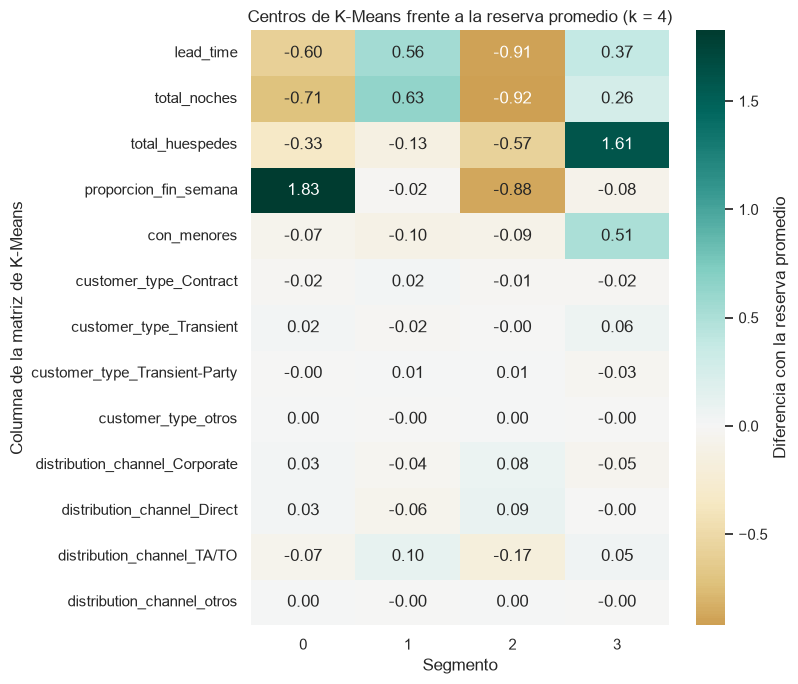

In [9]:
diferencia_centros = pd.DataFrame(
    kmeans.cluster_centers_ - Z_entrenamiento.mean(axis=0),
    columns=columnas_z,
).rename_axis("segmento")

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(diferencia_centros.T, cmap="BrBG", center=0, annot=True, fmt=".2f",
            cbar_kws={"label": "Diferencia con la reserva promedio"}, ax=ax)
ax.set_title(f"Centros de K-Means frente a la reserva promedio (k = {K_ELEGIDO})")
ax.set_xlabel("Segmento")
ax.set_ylabel("Columna de la matriz de K-Means")
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **Segmento 0 (13,4 %): estancias de fin de semana con poca anticipación.** Lo que más lo define es la proporción de noches de fin de semana, 1,83 desviaciones por encima del promedio, con menos anticipación (−0,60) y menos noches (−0,71).
- **Segmento 1 (45,5 %): reservas anticipadas y más largas.** Es el más grande. La anticipación (+0,56) y las noches (+0,63) quedan por encima del promedio, y casi no tiene menores.
- **Segmento 2 (25,5 %): última hora entre semana.** Todo queda por debajo del promedio: anticipación (−0,91), noches (−0,92) y fin de semana (−0,88). Es el que menos llega por *TA/TO* (−0,17) y el que más llega directo o por convenio corporativo.
- **Segmento 3 (15,5 %): viajes con menores.** Lo define el número de huéspedes (+1,61) y la proporción con menores, 51 puntos por encima del promedio, con algo más de anticipación y de noches que la reserva promedio.
- Las columnas del tipo de cliente no se apartan más de 0,06 del promedio en ningún segmento, y las del canal no más de 0,17. Los segmentos se arman con la anticipación, la duración, el fin de semana y el tamaño del grupo.

### 2.4 Cierre de K-Means

- Corrimos K-Means sobre las 63.351 reservas de entrenamiento con siete variables que se conocen al reservar, y escogimos *k* = 4. Las cuatro medidas no daban un ganador claro, así que decidimos entre 3 y 4 por lo que describían los segmentos, sin mirar la cancelación.
- Salieron cuatro perfiles que se entienden: estancias de fin de semana con poca anticipación (13,4 %), reservas anticipadas y más largas (45,5 %), reservas de última hora entre semana (25,5 %) y viajes con menores (15,5 %).
- El modelo tiene un Silhouette de 0,249, un Davies-Bouldin de 1,392 y un Calinski-Harabasz de 17.407. El Silhouette dice que la estructura es débil: los segmentos parten un continuo de reservas y no son tipos naturales bien separados, así que una reserva cerca de la frontera entre dos segmentos podría quedar en cualquiera de los dos.
- El tipo de cliente casi no influye en los segmentos, en parte por lo poco que pesa en las distancias (sección 1.4).

Lo que esto no permite concluir: todavía nada sobre las cancelaciones, porque no las usamos. Eso se mira en la sección 4, junto con el perfil completo de cada segmento y su estabilidad. Tampoco podemos decir que estos cuatro grupos sean los "verdaderos": con otro algoritmo o con otras variables las reservas se podrían partir distinto, y eso es justo lo que compara la sección 3.

Para la sección 3 quedan listos `crear_preparador()` y la matriz `Z_entrenamiento`, de la que el agrupamiento jerárquico puede sacar su muestra; `evaluar_agrupamiento`, para calcular las mismas medidas; y `segmentos_kmeans`, para comparar los dos métodos con el ARI.

## 3. Agrupamiento jerárquico y comparación de métodos

### 3.1 Por qué un agrupamiento jerárquico

La guía de las semanas 12-13 trabaja K-Means como modelo no supervisado, y el enunciado pide al menos dos algoritmos de agrupamiento. Para el segundo escogimos el agrupamiento jerárquico aglomerativo, que está en el capítulo 12 de *An Introduction to Statistical Learning*, uno de los que la guía manda repasar. Además funciona muy distinto a K-Means, y eso es lo que sirve para comparar: si un segmento aparece con los dos métodos, es más probable que esté en los datos y no que sea un efecto del algoritmo.

**Cómo funciona.** Empieza con cada reserva como un grupo aparte y, en cada paso, une los dos grupos más parecidos, hasta que todas quedan en un solo grupo. El resultado no es una partición sino un árbol de uniones, el **dendrograma**. La altura de cada unión dice qué tan distintos eran los grupos que se juntaron, y para obtener *k* grupos basta cortar el árbol a la altura donde quedan *k* ramas.

Qué tan "parecidos" son dos grupos depende del criterio de enlace. Usamos el de **Ward**: une los dos grupos que menos aumentan la suma de distancias al cuadrado de cada reserva al centro de su grupo. Es la misma cantidad que minimiza K-Means (la inercia), así que los dos métodos buscan grupos compactos y se pueden comparar con las mismas medidas. Lo que cambia es la estrategia: K-Means mueve centros hasta que se estabilizan, y Ward va uniendo grupos sin poder deshacer una unión.

Lo escogimos porque:

- **No hay que fijar *k* antes.** El árbol muestra todas las particiones posibles, y la altura de las uniones da una pista de cuántos grupos hay.
- **No depende de un punto de partida.** Con los mismos datos, el árbol sale siempre igual.
- **El dendrograma muestra cómo se relacionan los grupos**: cuáles se parecen entre sí y en qué orden se juntarían.

Sus supuestos son los mismos de K-Means en lo que toca a las distancias: que la distancia euclidiana tenga sentido, o sea, variables en escalas comparables. Por eso usamos la misma matriz de la sección 1.4. Ward, además, favorece grupos compactos y de dispersión parecida, igual que K-Means.

Sus limitaciones frente a estos datos:

- **No escala.** Necesita las distancias entre todos los pares de reservas, y esa cantidad crece con el cuadrado del número de reservas. Con las 63.351 no cabe en la memoria de un computador normal, así que trabajamos con una muestra (3.2).
- **Las uniones no se deshacen.** Si dos reservas quedan juntas por error al principio, el error se arrastra hasta arriba del árbol.
- **No asigna reservas nuevas.** Para ubicar una reserva nueva habría que rehacer el árbol, o asignarla al centro más cercano, que ya sería hacer lo mismo que K-Means.
- **Elegir dónde cortar sigue siendo una decisión nuestra**, igual que *k* en K-Means.

### 3.2 La muestra

Calculamos cuánta memoria ocupa la matriz de distancias con todas las reservas y con una muestra. Cada distancia ocupa 8 bytes y, como la distancia de A a B es la misma que de B a A, basta guardar la mitad de la matriz.

In [10]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage, set_link_color_palette
from sklearn.metrics import adjusted_rand_score

TAMANO_MUESTRA = 10_000
BYTES_POR_DISTANCIA = 8
RAMAS_DENDROGRAMA = 30
K_CANDIDATOS_WARD = (3, 4)
NOMBRES_SEGMENTOS_KMEANS = {
    0: "0 · fin de semana",
    1: "1 · anticipadas",
    2: "2 · última hora",
    3: "3 · con menores",
}


def memoria_distancias(n):
    """Número de distancias entre n reservas y gigabytes que ocupan."""
    distancias = n * (n - 1) // 2
    return {"reservas": n, "distancias": distancias, "memoria (GB)": distancias * BYTES_POR_DISTANCIA / 1e9}


pd.DataFrame([memoria_distancias(TAMANO_MUESTRA), memoria_distancias(len(Z_entrenamiento))],
             index=["muestra", "todas las reservas"]).round(1)

,reservas,distancias,memoria (GB)
muestra,10000,49995000,0.4
todas las reservas,63351,2006642925,16.1


Con las 63.351 reservas serían unos 2.000 millones de distancias, 16,1 GB solo para guardarlas, más de lo que tiene libre un computador normal y antes de empezar a unir grupos. Con una muestra de 10.000 reservas son unos 50 millones de distancias y 0,4 GB, que cabe sin problema. Escogimos 10.000 por eso y porque es el mismo tamaño de las muestras del Silhouette en la sección 2, así que las medidas de los dos métodos se calculan sobre la misma cantidad de reservas. Son el 15,8 % del entrenamiento. La sacamos al azar con `SEMILLA`, sin estratificar: no hay una etiqueta por la cual estratificar, y el muestreo aleatorio simple ya mantiene las proporciones cuando la muestra es grande.

Revisamos si la muestra se parece al entrenamiento completo en las variables numéricas, en las dos categóricas y en el reparto de los segmentos de K-Means.

In [11]:
generador = np.random.default_rng(SEMILLA)
indices_muestra = np.sort(generador.choice(len(Z_entrenamiento), size=TAMANO_MUESTRA, replace=False))
Z_muestra = Z_entrenamiento[indices_muestra]
X_muestra = X_segmentacion.iloc[indices_muestra]
kmeans_muestra = segmentos_kmeans[indices_muestra]


def resumen_para_comparar(datos, segmentos):
    """Promedios de las numéricas y porcentajes de las categorías principales y de los segmentos de K-Means."""
    resumen = datos[VARIABLES_LOGARITMO + VARIABLES_ESCALADAS + VARIABLES_BINARIAS].mean()
    resumen["Transient (%)"] = datos["customer_type"].eq("Transient").mean() * 100
    resumen["TA/TO (%)"] = datos["distribution_channel"].eq("TA/TO").mean() * 100
    porcentajes = pd.Series(segmentos).value_counts(normalize=True).sort_index() * 100
    for segmento, porcentaje in porcentajes.items():
        resumen[f"segmento K-Means {NOMBRES_SEGMENTOS_KMEANS[segmento]} (%)"] = porcentaje
    return resumen


pd.DataFrame({
    "muestra": resumen_para_comparar(X_muestra, kmeans_muestra),
    "entrenamiento completo": resumen_para_comparar(X_segmentacion, segmentos_kmeans),
}).round(3)

,muestra,entrenamiento completo
lead_time,78.106,77.426
total_noches,3.715,3.692
total_huespedes,2.042,2.059
proporcion_fin_semana,0.263,0.266
con_menores,0.110,0.112
Transient (%),85.840,86.144
TA/TO (%),79.860,79.550
segmento K-Means 0 · fin de semana (%),13.140,13.413
segmento K-Means 1 · anticipadas (%),46.150,45.543
segmento K-Means 2 · última hora (%),25.710,25.502


**¿Qué vemos?**

- La muestra se parece mucho al entrenamiento completo. La anticipación promedio es de 78,1 días contra 77,4, las noches de 3,72 contra 3,69 y los huéspedes de 2,04 contra 2,06. Las reservas con menores son el 11,0 % contra el 11,2 %, y las de tipo *Transient* y las que llegan por *TA/TO* no se apartan ni medio punto.
- Los cuatro segmentos de K-Means quedan representados casi en su proporción: ninguno se aparta más de 0,61 puntos (las anticipadas son el 46,15 % de la muestra y el 45,54 % del total).

Qué efecto puede tener la muestra: el árbol solo ve 10.000 reservas, así que un perfil muy pequeño, de unas pocas decenas de reservas en todo el entrenamiento, quedaría con muy pocas en la muestra y no alcanzaría a formar un grupo. Además, con otra muestra el árbol podría salir algo distinto. Qué tanto cambian los segmentos con otras muestras es lo que mide la sección 4.

### 3.3 El dendrograma y cuántos grupos

Construimos el árbol con el enlace de Ward sobre la muestra. Para que se pueda leer, el dendrograma muestra solo las últimas 30 uniones; el número entre paréntesis en cada rama es cuántas reservas tiene. Las líneas punteadas marcan dónde habría que cortar para quedarse con 3 o con 4 grupos. Además, en una tabla ponemos la altura de las últimas uniones: un salto grande entre una unión y la siguiente quiere decir que, para pasar de *k* a *k* − 1 grupos, toca juntar grupos bastante distintos, así que *k* es un buen candidato.

,altura de la unión que pasa de k a k − 1 grupos,salto frente a la unión anterior
k,,
2,130.5,20.9
3,109.6,21.1
4,88.5,13.9
5,74.6,4.8
6,69.7,8.9
7,60.8,4.7
8,56.1,10.0
9,46.1,5.3
10,40.8,0.3


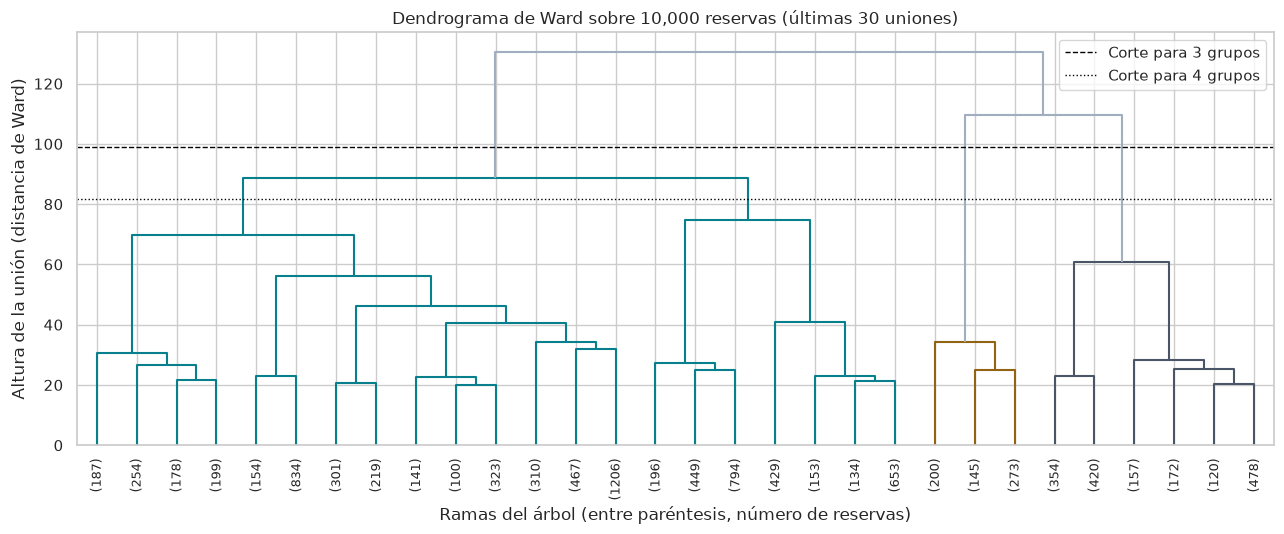

In [12]:
arbol_ward = linkage(Z_muestra, method="ward")
alturas = arbol_ward[:, 2]


def altura_de_corte(k):
    """Altura intermedia entre la unión que deja k grupos y la que deja k - 1."""
    return (alturas[-k] + alturas[-(k - 1)]) / 2


uniones = pd.DataFrame({
    "altura de la unión que pasa de k a k − 1 grupos": [alturas[-(k - 1)] for k in VALORES_K],
    "salto frente a la unión anterior": [alturas[-(k - 1)] - alturas[-k] for k in VALORES_K],
}, index=pd.Index(VALORES_K, name="k"))
display(uniones.round(1))

set_link_color_palette([COLOR_PRINCIPAL, COLOR_RIESGO, "#4A5568"])
fig, ax = plt.subplots(figsize=(13, 5.5))
dendrogram(arbol_ward, truncate_mode="lastp", p=RAMAS_DENDROGRAMA, show_leaf_counts=True,
           color_threshold=altura_de_corte(3), above_threshold_color=COLOR_SECUNDARIO,
           leaf_rotation=90, leaf_font_size=9, ax=ax)
for k, estilo in zip(K_CANDIDATOS_WARD, ("--", ":")):
    ax.axhline(altura_de_corte(k), color="black", linestyle=estilo, linewidth=1, label=f"Corte para {k} grupos")
ax.set_title(f"Dendrograma de Ward sobre {TAMANO_MUESTRA:,} reservas (últimas {RAMAS_DENDROGRAMA} uniones)")
ax.set_xlabel("Ramas del árbol (entre paréntesis, número de reservas)")
ax.set_ylabel("Altura de la unión (distancia de Ward)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
set_link_color_palette(None)

Calculamos las mismas medidas de la sección 2.2 para cada corte del árbol, de 2 a 10 grupos. Como la muestra tiene exactamente 10.000 reservas, el Silhouette se calcula con todas ellas y las tres repeticiones dan lo mismo (desviación 0). Agregamos el ARI contra K-Means, que explicamos en la 3.5.

In [13]:
def cortar_arbol(k):
    """Etiquetas de 0 a k - 1 al cortar el árbol de Ward en k grupos."""
    return fcluster(arbol_ward, t=k, criterion="maxclust") - 1


filas = []
etiquetas_ward = {}
for k in VALORES_K:
    etiquetas_ward[k] = cortar_arbol(k)
    filas.append({
        "k": k,
        **evaluar_agrupamiento(Z_muestra, etiquetas_ward[k]),
        "grupo más pequeño": np.bincount(etiquetas_ward[k]).min(),
        "ARI con K-Means (k = 4)": adjusted_rand_score(kmeans_muestra, etiquetas_ward[k]),
    })
metricas_ward = pd.DataFrame(filas).set_index("k")
metricas_ward.round(3)

,Silhouette,Silhouette (desviación),Davies-Bouldin,Calinski-Harabasz,grupo más pequeño,ARI con K-Means (k = 4)
k,,,,,,
2,0.276,0.0,1.799,2240.703,2319,0.253
3,0.280,0.0,1.230,2269.777,618,0.281
4,0.189,0.0,1.615,2189.546,618,0.422
5,0.168,0.0,1.382,2097.643,618,0.493
6,0.196,0.0,1.437,2069.302,618,0.472
7,0.210,0.0,1.405,2022.854,618,0.437
8,0.182,0.0,1.420,1989.686,618,0.322
9,0.184,0.0,1.400,1913.659,520,0.311
10,0.193,0.0,1.395,1834.160,429,0.285


**¿Qué vemos?**

- **El dendrograma apunta a 2 o 3 grupos.** Los saltos más grandes son los de las dos últimas uniones: 20,9 para pasar de 2 grupos a 1 y 21,1 para pasar de 3 a 2. El de 4 a 3 es de 13,9, y de ahí para abajo ninguno pasa de 10,0. En la gráfica se ve: entre la línea del corte para 3 grupos y las uniones de arriba hay un tramo largo sin uniones.
- **Las tres medidas coinciden en *k* = 3**, algo que no pasó con K-Means. Con 3 grupos el Silhouette es el más alto (0,280), el Davies-Bouldin el más bajo (1,230) y el Calinski-Harabasz el más alto (2.269,8). Con 4 grupos el Silhouette cae a 0,189 y el Davies-Bouldin sube a 1,615.
- Desde *k* = 3 aparece un grupo de 618 reservas que sigue siendo el más pequeño en todos los cortes hasta *k* = 8. Es un grupo compacto y bien separado de los demás: el árbol lo mantiene entero aunque parta todos los otros.
- El Silhouette sigue siendo bajo, por debajo de 0,3 en todos los cortes: igual que con K-Means, la estructura es débil.

Para decidir entre 3 y 4 miramos qué describe cada grupo, con la misma función que usamos para K-Means en la 2.2. Le agregamos el porcentaje de estancias de una noche y la estancia más larga de cada grupo.

In [14]:
def etiquetas_en_entrenamiento(etiquetas_muestra):
    """Lleva las etiquetas de la muestra al tamaño del entrenamiento, vacías fuera de la muestra."""
    etiquetas = pd.Series(pd.NA, index=X_segmentacion.index, dtype="Int64")
    etiquetas.iloc[indices_muestra] = etiquetas_muestra
    return etiquetas


for k in K_CANDIDATOS_WARD:
    etiquetas = etiquetas_en_entrenamiento(etiquetas_ward[k])
    noches = X_segmentacion["total_noches"].groupby(etiquetas).agg(
        una_noche=lambda total: total.eq(1).mean() * 100,
        noches_maximo="max",
    ).rename(columns={"una_noche": "una_noche (%)"})
    print(f"Ward con k = {k}")
    display(describir_centros(etiquetas).join(noches).round(1))

Ward con k = 3


,reservas,anticipacion_mediana,noches_mediana,fin_de_semana (%),huespedes_promedio,con_menores (%),transient (%),canal_ta_to (%),canal_directo_o_corporativo (%),una_noche (%),noches_maximo
grupo,,,,,,,,,,,
0,7681,72.0,4.0,26.2,2.1,12.1,85.4,86.1,13.8,5.4,46
1,618,11.0,1.0,99.9,1.8,7.0,89.8,69.6,30.3,71.2,3
2,1701,3.0,1.0,0.0,1.7,7.6,86.2,55.4,43.8,63.7,5


Ward con k = 4


,reservas,anticipacion_mediana,noches_mediana,fin_de_semana (%),huespedes_promedio,con_menores (%),transient (%),canal_ta_to (%),canal_directo_o_corporativo (%),una_noche (%),noches_maximo
grupo,,,,,,,,,,,
0,4873,72.0,4.0,34.5,1.9,1.8,79.8,86.0,13.9,1.0,46
1,2808,74.0,3.0,12.0,2.6,29.8,95.3,86.2,13.8,13.0,19
2,618,11.0,1.0,99.9,1.8,7.0,89.8,69.6,30.3,71.2,3
3,1701,3.0,1.0,0.0,1.7,7.6,86.2,55.4,43.8,63.7,5


**¿Qué vemos?**

- **Con *k* = 3**, Ward aparta dos grupos pequeños y muy definidos y deja el resto junto:
  - **Grupo 1 (618 reservas): estancias cortas de fin de semana.** El 71,2 % es de una noche y ninguna pasa de 3, el 99,9 % de las noches cae en sábado o domingo y la anticipación mediana es de 11 días.
  - **Grupo 2 (1.701 reservas): estancias cortas entre semana, de último minuto.** El 63,7 % es de una noche y ninguna pasa de 5, ninguna noche cae en fin de semana y la anticipación mediana es de 3 días. Es el grupo con más reservas directas o corporativas (43,8 %).
  - **Grupo 0 (7.681 reservas): todo lo demás.** Anticipación mediana de 72 días y 4 noches; solo el 5,4 % es de una noche.
- **Con *k* = 4**, el grupo grande se parte en dos: 4.873 reservas casi sin menores (1,8 %) y 2.808 con 2,6 huéspedes en promedio, de las que el 29,8 % viaja con menores. Ese grupo se parece al segmento de viajes con menores de K-Means, pero mucho menos marcado: allá el 62,3 % de las reservas tenía menores.

**Decisión: *k* = 3.** En K-Means escogimos 4 porque el cuarto grupo costaba solo 0,017 de Silhouette y separaba un perfil claro. Aquí el cuarto grupo cuesta 0,091 de Silhouette (de 0,280 a 0,189), empeora el Davies-Bouldin y el grupo nuevo es una mezcla en la que la mayoría de las reservas no lleva menores. El dendrograma, las tres medidas y la lectura de los grupos apuntan a lo mismo.

### 3.4 El modelo jerárquico con *k* = 3

Comparamos cada grupo de Ward con la reserva promedio en la matriz del agrupamiento, como hicimos con los centros de K-Means en la 2.3.

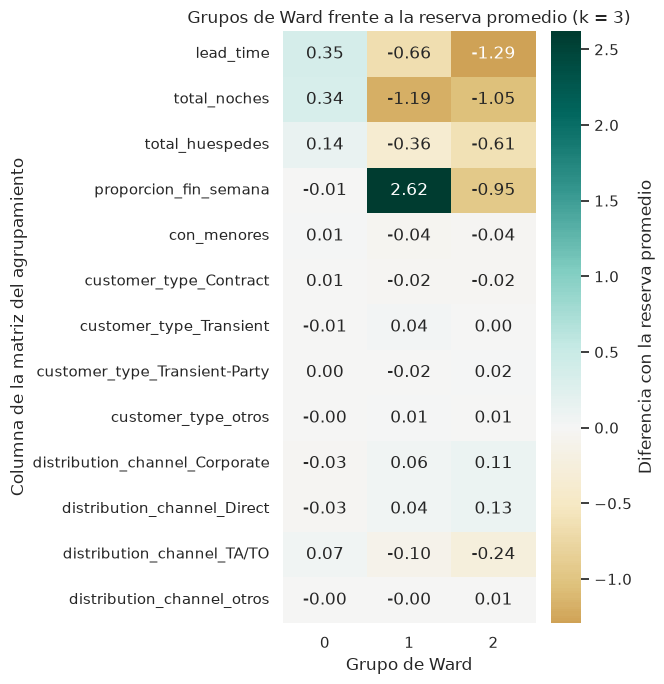

In [15]:
K_WARD = 3

segmentos_ward = etiquetas_ward[K_WARD]
diferencia_grupos_ward = pd.DataFrame(
    [Z_muestra[segmentos_ward == grupo].mean(axis=0) - Z_entrenamiento.mean(axis=0) for grupo in range(K_WARD)],
    columns=columnas_z,
).rename_axis("grupo de Ward")

fig, ax = plt.subplots(figsize=(6.5, 7))
sns.heatmap(diferencia_grupos_ward.T, cmap="BrBG", center=0, annot=True, fmt=".2f",
            cbar_kws={"label": "Diferencia con la reserva promedio"}, ax=ax)
ax.set_title(f"Grupos de Ward frente a la reserva promedio (k = {K_WARD})")
ax.set_xlabel("Grupo de Ward")
ax.set_ylabel("Columna de la matriz del agrupamiento")
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **Grupo 1 (6,2 % de la muestra):** lo define la proporción de noches de fin de semana, 2,62 desviaciones por encima del promedio, con menos noches (−1,19) y menos anticipación (−0,66).
- **Grupo 2 (17,0 %):** todo por debajo del promedio, sobre todo la anticipación (−1,29), las noches (−1,05) y el fin de semana (−0,95). Es el único que se aparta algo en el canal: menos *TA/TO* (−0,24) y más directo (+0,13) y corporativo (+0,11).
- **Grupo 0 (76,8 %):** queda cerca del promedio en todo; lo más alto es la anticipación, con +0,35. Es lo que queda cuando se sacan los dos grupos extremos, no un perfil propio.
- El tipo de cliente no se aparta más de 0,04 del promedio en ningún grupo. Igual que en K-Means, pesa poco en las distancias (sección 1.4).

### 3.5 Comparación de K-Means y Ward

Comparamos los dos métodos **sobre la misma muestra**. Las medidas de K-Means de la sección 2 se calcularon con las 63.351 reservas, y el Calinski-Harabasz crece con el número de reservas, así que no se puede poner al lado de uno calculado con 10.000. Por eso recalculamos las medidas de K-Means solo con las reservas de la muestra, usando los segmentos que ya tenía; K-Means no se vuelve a entrenar.

Para medir si los dos métodos coinciden usamos el **índice de Rand ajustado (ARI)**. El índice de Rand mira todos los pares de reservas y cuenta en cuántos los dos métodos están de acuerdo, ya sea porque los dos las ponen juntas o porque los dos las separan. El ajuste le resta el acuerdo que se esperaría por azar: un ARI de 1 es la misma partición, uno cercano a 0 es lo que daría repartir al azar, y no importa cómo se numeren los grupos ni que los dos métodos tengan distinto *k*.

In [16]:
comparacion_metodos = pd.DataFrame({
    "K-Means (k = 4)": evaluar_agrupamiento(Z_muestra, kmeans_muestra),
    "Ward (k = 3)": evaluar_agrupamiento(Z_muestra, segmentos_ward),
    "Ward (k = 4)": evaluar_agrupamiento(Z_muestra, etiquetas_ward[4]),
}).T.drop(columns="Silhouette (desviación)")
comparacion_metodos["grupo más grande (%)"] = [
    pd.Series(etiquetas).value_counts(normalize=True).max() * 100
    for etiquetas in (kmeans_muestra, segmentos_ward, etiquetas_ward[4])
]
comparacion_metodos["ARI con K-Means (k = 4)"] = [
    1.0,
    adjusted_rand_score(kmeans_muestra, segmentos_ward),
    adjusted_rand_score(kmeans_muestra, etiquetas_ward[4]),
]
comparacion_metodos.round(3)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,grupo más grande (%),ARI con K-Means (k = 4)
K-Means (k = 4),0.247,1.393,2729.033,46.15,1.000
Ward (k = 3),0.280,1.230,2269.777,76.81,0.281
Ward (k = 4),0.189,1.615,2189.546,48.73,0.422


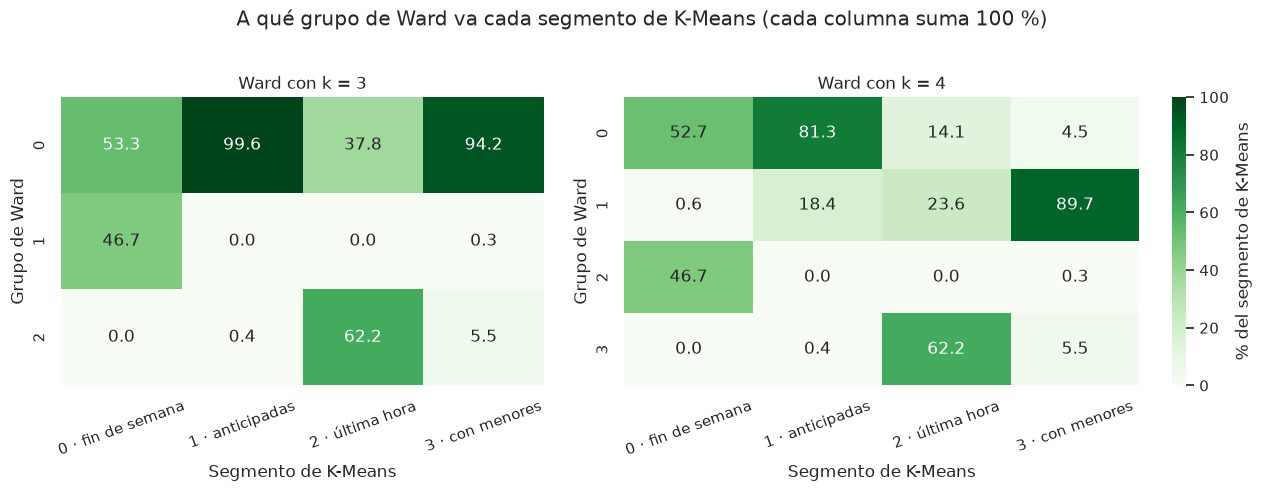

In [17]:
def tabla_cruzada(etiquetas_ward_k):
    """Porcentaje de cada segmento de K-Means que cae en cada grupo de Ward."""
    return pd.crosstab(
        pd.Series(etiquetas_ward_k, name="Grupo de Ward"),
        pd.Series(kmeans_muestra, name="Segmento de K-Means").map(NOMBRES_SEGMENTOS_KMEANS),
        normalize="columns",
    ) * 100


fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [3, 4]})
for ax, k in zip(ejes, K_CANDIDATOS_WARD):
    sns.heatmap(tabla_cruzada(etiquetas_ward[k]), cmap="Greens", vmin=0, vmax=100, annot=True, fmt=".1f",
                cbar=ax is ejes[-1], cbar_kws={"label": "% del segmento de K-Means"}, ax=ax)
    ax.set_title(f"Ward con k = {k}")
    ax.set_xlabel("Segmento de K-Means")
    ax.set_ylabel("Grupo de Ward")
    ax.tick_params(axis="x", rotation=20)
plt.suptitle("A qué grupo de Ward va cada segmento de K-Means (cada columna suma 100 %)", y=1.02)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **Cada método gana en una medida distinta.** En la misma muestra, Ward con *k* = 3 tiene mejor Silhouette (0,280 contra 0,247) y mejor Davies-Bouldin (1,230 contra 1,393), y K-Means tiene mejor Calinski-Harabasz (2.729,0 contra 2.269,8). Las medidas de Ward son mejores porque aparta dos grupos pequeños y compactos, pero a cambio deja el 76,81 % de las reservas en un solo grupo. K-Means reparte mejor: su grupo más grande tiene el 46,15 %. Ward con *k* = 4 queda por debajo de K-Means en las tres medidas.
- **Los dos métodos coinciden poco.** El ARI entre K-Means y Ward con *k* = 3 es de 0,281, y con *k* = 4 de 0,422. Están más de acuerdo de lo que daría el azar, pero lejos de dar la misma partición.
- **La tabla cruzada muestra en qué coinciden y en qué no:**
  - El 62,2 % de las reservas de **última hora** de K-Means quedan en el grupo de estancias cortas entre semana de Ward. Las demás quedan en el grupo grande: K-Means junta en ese segmento reservas de poca anticipación y pocas noches, y Ward solo aparta las más extremas, de anticipación mínima y ninguna noche de fin de semana.
  - El 46,7 % del segmento de **fin de semana** de K-Means quedan en el grupo de estancias cortas de fin de semana de Ward. El resto son estancias que caen en parte en fin de semana, o más largas, y Ward las deja en el grupo grande.
  - Las **anticipadas** de K-Means quedan casi todas (99,6 %) en el grupo grande de Ward, igual que el 94,2 % de los **viajes con menores**.
  - Con *k* = 4, Ward manda el 89,7 % de los viajes con menores de K-Means a un mismo grupo, pero ese grupo también recibe el 18,4 % de las anticipadas y el 23,6 % de las de última hora. Por eso solo el 29,8 % de sus reservas lleva menores.

Lo que se repite con los dos métodos es un núcleo de estancias cortas entre semana con muy poca anticipación y otro de estancias cortas de fin de semana. Esos dos perfiles los encuentran dos algoritmos que trabajan distinto, así que es más probable que estén en los datos. Lo que cambia según el método es cómo se parte el resto, sobre todo dónde termina la estancia corta y empieza la larga y si los viajes con menores son un grupo aparte. Eso cuadra con el Silhouette bajo: las reservas forman un continuo, y cada método lo corta por un lado distinto.

### 3.6 Cierre de la sección

- Como segundo método usamos el agrupamiento jerárquico aglomerativo con enlace de Ward, sobre una muestra aleatoria de 10.000 reservas que se parece al entrenamiento completo. Con todas las reservas la matriz de distancias ocuparía 16,1 GB.
- El dendrograma y las tres medidas coinciden en *k* = 3: dos grupos pequeños y compactos, estancias cortas de fin de semana (6,2 %) y estancias cortas entre semana de último minuto (17,0 %), y un grupo grande con el resto (76,8 %).
- En la misma muestra, Ward tiene mejor Silhouette (0,280 contra 0,247) y Davies-Bouldin (1,230 contra 1,393), y K-Means mejor Calinski-Harabasz. Los dos tienen un Silhouette por debajo de 0,3, o sea una estructura débil.
- Los dos métodos coinciden poco (ARI de 0,281), pero los dos encuentran los perfiles de estancias cortas, entre semana y de fin de semana.

**Para la sección 4 recomendamos seguir con los segmentos de K-Means (*k* = 4).** Trabaja con las 63.351 reservas y no con una muestra, puede ubicar una reserva nueva en su segmento, reparte las reservas en grupos de tamaño útil para el hotel y contiene los dos núcleos que también encontró Ward. Las medidas de Ward son algo mejores, pero sobre todo porque deja tres de cada cuatro reservas en un solo grupo, y eso no le sirve al hotel para tratar distinto a cada perfil.

Lo que esta sección no permite concluir: todavía nada sobre las cancelaciones, porque ninguno de los dos métodos las usó. Tampoco que uno de los dos sea el correcto. Un ARI bajo no quiere decir que uno se equivoque, sino que las reservas no tienen fronteras naturales y cada método las traza distinto. Y el resultado de Ward es de una sola muestra.

Para la sección 4 quedan listos `segmentos_kmeans`, la segmentación recomendada; `segmentos_ward` e `indices_muestra`, por si se quiere comparar los perfiles con los de Ward; y `cortar_arbol` y `NOMBRES_SEGMENTOS_KMEANS`.

## 4. Perfiles y estabilidad de los segmentos

Seguimos con los cuatro segmentos de K-Means, como recomendó la sección 3. En esta sección hacemos tres cosas:

1. Describimos cada segmento con las variables del agrupamiento y también con las que no entraron (hotel, segmento de mercado, agencia, historial del cliente, mes de llegada), y le ponemos un nombre.
2. Medimos qué tan estables son: si repetimos K-Means con otras semillas o con otras muestras de reservas, ¿salen los mismos segmentos?
3. Ya con los segmentos armados, miramos cuánto cancela cada uno. `is_canceled` no entró al agrupamiento; aquí solo se usa para leer los grupos, como permite el enunciado.

El orden importa por lo mismo de la sección 1.1: si primero miráramos la cancelación y después le pusiéramos nombre a los segmentos, sería fácil acomodar la descripción a lo que queremos encontrar.

In [18]:
from scipy.optimize import linear_sum_assignment
from scipy.stats import chi2_contingency

RUTA_PRUEBA = Path("../data/processed/prueba.csv.gz")
NOMBRES_PERFILES = {
    0: "Escapadas de fin de semana",
    1: "Anticipadas y largas",
    2: "Última hora entre semana",
    3: "Viajes con menores",
}
ORDEN_PERFILES = list(NOMBRES_PERFILES.values())
N_SEMILLAS = 10
N_SUBMUESTRAS = 10
FRACCION_SUBMUESTRA = 0.8
SEGMENTOS_MERCADO_PRINCIPALES = ["Online TA", "Offline TA/TO", "Direct", "Groups", "Corporate"]
MESES_VERANO = [7, 8]
TODAS = "Todas las reservas"


def nombrar(segmentos):
    """Serie con el nombre del perfil de cada reserva, en el orden fijo de los perfiles."""
    return pd.Series(pd.Categorical(pd.Series(segmentos).map(NOMBRES_PERFILES), categories=ORDEN_PERFILES))


perfil_entrenamiento = nombrar(segmentos_kmeans)
perfil_entrenamiento.index = entrenamiento.index

### 4.1 Perfil y composición de cada segmento

Para cada segmento calculamos los valores típicos de las siete variables del agrupamiento y, al lado, variables que no entraron: el hotel, el segmento de mercado, si la reserva tiene agencia o empresa, el historial del cliente y si llega en julio o agosto. Que esas variables cambien de un segmento a otro sin haber entrado al agrupamiento es una forma de ver si los perfiles describen algo más que las variables con que se armaron. La última columna es el promedio de todas las reservas, para comparar.

In [19]:
def perfil(datos):
    """Valores típicos de un grupo de reservas, con variables del agrupamiento y de fuera de él."""
    return {
        "reservas": len(datos),
        "anticipación mediana (días)": datos["lead_time"].median(),
        "noches mediana": datos["total_noches"].median(),
        "noches de fin de semana (%)": (datos["stays_in_weekend_nights"] / datos["total_noches"]).mean() * 100,
        "huéspedes promedio": datos["total_huespedes"].mean(),
        "con menores (%)": (datos["children"] + datos["babies"]).gt(0).mean() * 100,
        "Transient (%)": datos["customer_type"].eq("Transient").mean() * 100,
        "canal TA/TO (%)": datos["distribution_channel"].eq("TA/TO").mean() * 100,
        "City Hotel (%)": datos["hotel"].eq("City Hotel").mean() * 100,
        "llegada en julio o agosto (%)": datos["mes_llegada"].isin(MESES_VERANO).mean() * 100,
        "segmento Online TA (%)": datos["market_segment"].eq("Online TA").mean() * 100,
        "segmento Offline TA/TO o Groups (%)": datos["market_segment"].isin(["Offline TA/TO", "Groups"]).mean() * 100,
        "sin agencia (%)": datos["agent"].astype(str).eq("Sin agente").mean() * 100,
        "con empresa (%)": datos["tiene_empresa"].mean() * 100,
        "cliente repetido (%)": datos["is_repeated_guest"].mean() * 100,
    }


perfiles = pd.DataFrame({
    **{nombre: perfil(entrenamiento[perfil_entrenamiento == nombre]) for nombre in ORDEN_PERFILES},
    TODAS: perfil(entrenamiento),
})
perfiles.loc["porcentaje de las reservas"] = perfiles.loc["reservas"] / len(entrenamiento) * 100
perfiles.round(1)

,Escapadas de fin de semana,Anticipadas y largas,Última hora entre semana,Viajes con menores,Todas las reservas
reservas,8497.0,28852.0,16156.0,9846.0,63351.0
anticipación mediana (días),14.0,97.0,6.0,77.0,48.0
noches mediana,2.0,4.0,1.0,4.0,3.0
noches de fin de semana (%),77.7,26.1,2.1,24.5,26.6
huéspedes promedio,1.8,1.9,1.7,3.4,2.1
con menores (%),4.2,0.9,2.3,62.3,11.2
Transient (%),87.9,83.8,85.9,91.8,86.1
canal TA/TO (%),73.0,89.5,62.2,84.5,79.6
City Hotel (%),67.2,58.7,60.5,65.3,61.3
llegada en julio o agosto (%),18.8,26.8,15.9,41.9,25.3


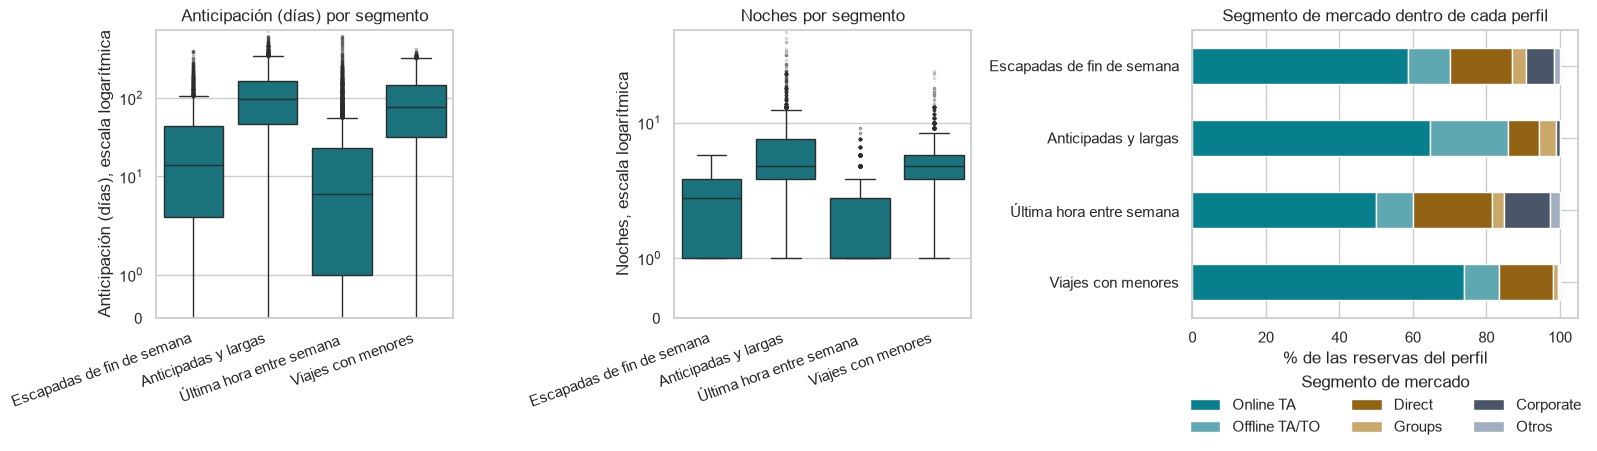

In [20]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.3]})
datos_grafica = entrenamiento.assign(perfil=perfil_entrenamiento)

for ax, (columna, titulo) in zip(ejes[:2], [("lead_time", "Anticipación (días)"), ("total_noches", "Noches")]):
    sns.boxplot(data=datos_grafica, x="perfil", y=columna, order=ORDEN_PERFILES, color=COLOR_PRINCIPAL,
                flierprops={"markersize": 1.5, "alpha": 0.2}, ax=ax)
    ax.set_yscale("symlog")
    ax.set_ylim(bottom=0)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{titulo} por segmento")
    ax.set_xlabel("")
    ax.set_ylabel(f"{titulo}, escala logarítmica")
    ax.tick_params(axis="x", rotation=20)
    for etiqueta in ax.get_xticklabels():
        etiqueta.set_horizontalalignment("right")

mercado = datos_grafica["market_segment"].where(datos_grafica["market_segment"].isin(SEGMENTOS_MERCADO_PRINCIPALES), "Otros")
composicion = pd.crosstab(datos_grafica["perfil"], mercado, normalize="index")[SEGMENTOS_MERCADO_PRINCIPALES + ["Otros"]] * 100
colores_mercado = [COLOR_PRINCIPAL, "#5FA8B1", COLOR_RIESGO, "#C9A86A", "#4A5568", COLOR_SECUNDARIO]
composicion.loc[ORDEN_PERFILES].plot.barh(stacked=True, color=colores_mercado, edgecolor="white", ax=ejes[2])
ejes[2].invert_yaxis()
ejes[2].set_title("Segmento de mercado dentro de cada perfil")
ejes[2].set_xlabel("% de las reservas del perfil")
ejes[2].set_ylabel("")
ejes[2].legend(title="Segmento de mercado", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=3, frameon=False)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

Los cuatro nombres salen de lo que describió la 2.3, y la tabla los confirma con variables que no entraron al agrupamiento.

Las escapadas de fin de semana (13,4 % de las reservas) son estancias cortas, con mediana de 2 noches y el 77,7 % de las noches en sábado o domingo, que se reservan con poca anticipación (mediana de 14 días). Por fuera del agrupamiento, tienen más reservas sin agencia (20,0 %) y más clientes repetidos (6,3 %) que el promedio (13,1 % y 3,9 %), y en la gráfica se ve que *Direct* pesa más que en las anticipadas.

Las anticipadas y largas son casi la mitad (45,5 %): mediana de 97 días de anticipación y 4 noches, y casi sin menores (0,9 %). Son las más ligadas a las agencias: el 89,5 % llega por *TA/TO*, solo el 4,5 % no tiene agencia, y es el perfil con más *Offline TA/TO* o *Groups* (25,7 %).

Las de última hora entre semana (25,5 %) se reservan con 6 días de mediana, para 1 noche, y casi nunca caen en fin de semana (2,1 % de las noches). Es el perfil con más reservas sin agencia (29,3 %), con empresa (13,8 %) y de clientes repetidos (10,2 %), y el que menos llega por *TA/TO* (62,2 %). Eso suena a viajes de trabajo, pero es una lectura nuestra: el dataset no dice para qué es el viaje.

Los viajes con menores (15,5 %) tienen 3,4 huéspedes en promedio y el 62,3 % lleva niños o bebés. Se reservan con tiempo (77 días de mediana) y son los más concentrados en vacaciones: el 41,9 % llega en julio o agosto, contra 25,3 % del total. También son los que más llegan por *Online TA* (73,8 %).

El hotel cambia poco de un perfil a otro: el City Hotel tiene entre 58,7 % y 67,2 % de las reservas en los cuatro. O sea que los perfiles no son un hotel contra el otro. El tipo de cliente tampoco cambia mucho (entre 83,8 % y 91,8 % de *Transient*), como ya se había visto en la 2.3.

Lo que esto no permite concluir: los nombres simplifican. En la gráfica las cajas de anticipación de las anticipadas y de los viajes con menores se traslapan bastante, y con un Silhouette de 0,249 hay muchas reservas cerca de la frontera entre dos perfiles.

### 4.2 Estabilidad de los segmentos

Un segmento solo le sirve al hotel si sale parecido cada vez que se calcula. Lo medimos de tres formas, siempre con el ARI que explicó la 3.5 y comparando contra los segmentos de la sección 2:

1. **Otras semillas.** Repetimos K-Means con *k* = 4 sobre las mismas reservas, con 10 semillas distintas. Mide si el resultado depende del punto de partida.
2. **Otras muestras.** Sacamos 10 muestras al azar del 80 % del entrenamiento, ajustamos en cada una la preparación y K-Means desde cero y asignamos con ese modelo todas las reservas de entrenamiento. Mide si los segmentos dependen de qué reservas tocaron.
3. **Reservas que el agrupamiento no vio.** Tomamos la prueba que dejó el notebook 02 y le asignamos un segmento con el modelo de la sección 2. Por aparte, ajustamos un K-Means nuevo solo con la prueba y comparamos las dos asignaciones. Aquí la prueba solo aporta sus variables, sin `is_canceled`, y no se decide nada con ella.

El ARI resume toda la partición en un número. Para saber cuál segmento es el que se mueve, además emparejamos los segmentos de cada repetición con los de la sección 2 (cada uno con el que más reservas comparte) y medimos qué porcentaje de cada segmento original cae en su pareja.

In [21]:
def ajustar_segmentos(datos, semilla):
    """Preparación y K-Means con k = 4 ajustados desde cero con las reservas dadas."""
    modelo = make_pipeline(crear_preparador(), KMeans(n_clusters=K_ELEGIDO, n_init=N_INICIOS, random_state=semilla))
    return modelo.fit(datos)


def permanencia_por_segmento(referencia, nuevos):
    """% de cada segmento de referencia que cae en el segmento nuevo que mejor le corresponde."""
    cruce = pd.crosstab(referencia, nuevos).to_numpy()
    filas, columnas = linear_sum_assignment(-cruce)
    return pd.Series(cruce[filas, columnas] / cruce[filas].sum(axis=1) * 100, index=filas)


repeticiones = []
for semilla in range(SEMILLA + 1, SEMILLA + 1 + N_SEMILLAS):
    modelo_semilla = crear_kmeans(K_ELEGIDO).set_params(random_state=semilla).fit(Z_entrenamiento)
    repeticiones.append(("otra semilla", semilla, modelo_semilla.labels_, modelo_semilla.inertia_))

generador_submuestras = np.random.default_rng(SEMILLA)
for repeticion in range(N_SUBMUESTRAS):
    filas_submuestra = generador_submuestras.choice(len(X_segmentacion), size=int(FRACCION_SUBMUESTRA * len(X_segmentacion)),
                                                    replace=False)
    modelo = ajustar_segmentos(X_segmentacion.iloc[filas_submuestra], SEMILLA)
    repeticiones.append(("otra muestra del 80 %", repeticion, modelo.predict(X_segmentacion), np.nan))

estabilidad = pd.DataFrame([
    {"prueba": tipo, "repetición": numero, "ARI": adjusted_rand_score(segmentos_kmeans, nuevos),
     "inercia frente a la de la sección 2 (%)": (inercia / kmeans.inertia_ - 1) * 100,
     **permanencia_por_segmento(segmentos_kmeans, nuevos).rename(NOMBRES_PERFILES).to_dict()}
    for tipo, numero, nuevos, inercia in repeticiones
])
display(estabilidad.groupby("prueba")[["ARI", *ORDEN_PERFILES]].agg(["mean", "min"]).round(3).T)

print("Detalle de las 10 semillas:")
estabilidad.query("prueba == 'otra semilla'").drop(columns="prueba").set_index("repetición").round(3)

prueba                           otra muestra del 80 %  otra semilla
ARI                        mean                  0.991         0.942
                           min                   0.975         0.460
Escapadas de fin de semana mean                 99.563        99.286
                           min                  96.764        93.974
Anticipadas y largas       mean                 99.670        97.506
                           min                  99.168        76.546
Última hora entre semana   mean                 99.636        96.482
                           min                  98.508        66.421
Viajes con menores         mean                 99.946        93.448
                           min                  99.878        34.704

Detalle de las 10 semillas:


,ARI,inercia frente a la de la sección 2 (%),Escapadas de fin de semana,Anticipadas y largas,Última hora entre semana,Viajes con menores
repetición,,,,,,
43,0.999,0.000,100.000,99.941,100.000,100.000
44,0.994,0.000,100.000,99.536,99.994,99.909
45,0.977,0.007,99.047,99.165,98.787,99.868
46,1.000,0.000,100.000,100.000,99.975,100.000
47,0.999,0.000,100.000,99.948,99.994,100.000
48,0.460,0.563,93.974,76.546,66.421,34.704
49,0.998,0.000,99.953,99.993,99.808,100.000
50,0.998,0.000,99.882,100.000,99.870,100.000
51,1.000,0.000,100.000,100.000,99.975,100.000


In [22]:
prueba = pd.read_csv(RUTA_PRUEBA)
X_prueba_segmentacion = variables_de_segmentacion(prueba)
assert OBJETIVO not in X_prueba_segmentacion.columns

segmentos_prueba = kmeans.predict(preparador.transform(X_prueba_segmentacion))
segmentos_prueba_propios = ajustar_segmentos(X_prueba_segmentacion, SEMILLA).predict(X_prueba_segmentacion)

tamanos_comparados = pd.DataFrame({
    "entrenamiento (%)": perfil_entrenamiento.value_counts(normalize=True) * 100,
    "prueba (%)": nombrar(segmentos_prueba).value_counts(normalize=True) * 100,
}).loc[ORDEN_PERFILES]
display(tamanos_comparados.round(1))
print(f"Prueba: {len(prueba):,} reservas")
print(f"ARI entre el modelo de entrenamiento y un K-Means ajustado solo con la prueba: "
      f"{adjusted_rand_score(segmentos_prueba, segmentos_prueba_propios):.3f}")
print("Permanencia por segmento (%):",
      permanencia_por_segmento(segmentos_prueba, segmentos_prueba_propios).rename(NOMBRES_PERFILES).round(1).to_dict())

,entrenamiento (%),prueba (%)
Escapadas de fin de semana,13.4,13.6
Anticipadas y largas,45.5,45.7
Última hora entre semana,25.5,25.5
Viajes con menores,15.5,15.2


Prueba: 15,839 reservas
ARI entre el modelo de entrenamiento y un K-Means ajustado solo con la prueba: 0.961
Permanencia por segmento (%): {'Escapadas de fin de semana': 98.9, 'Anticipadas y largas': 98.2, 'Última hora entre semana': 98.1, 'Viajes con menores': 99.7}


**¿Qué vemos?**

Frente a la muestra, los segmentos son muy estables. En las 10 muestras del 80 % el ARI promedio con los segmentos de la sección 2 es de 0,991 y el más bajo de 0,975, y cada segmento conserva en promedio más del 99,5 % de sus reservas. Con la prueba pasa lo mismo: los cuatro perfiles tienen casi el mismo tamaño que en entrenamiento (la diferencia más grande es de 0,3 puntos, en los viajes con menores), y un K-Means ajustado solo con esas 15.839 reservas coincide con el de entrenamiento con un ARI de 0,961. O sea que los perfiles no dependen de qué reservas usemos.

Con las semillas hay un caso que se sale. Nueve de las diez dan prácticamente los mismos segmentos (ARI de 0,977 o más), pero la semilla 48 llega a otra partición, con un ARI de 0,460, en la que los viajes con menores solo conservan el 34,7 % de sus reservas. Esa partición tiene una inercia 0,563 % mayor. O sea que es un mínimo local peor, de esos en los que K-Means puede caer según el punto de partida, como advertía la 2.1. Como K-Means se queda con el punto de partida de menor inercia, nuestros segmentos son la mejor solución que encontró, y la misma que repiten las otras nueve semillas.

Igual queda una advertencia: los viajes con menores son el segmento más frágil. Es justo el que no aparecía con *k* = 3 y el que Ward no separó con *k* = 3. Si alguien vuelve a correr K-Means con menos puntos de partida, puede que no le salga.

### 4.3 Cuánto cancela cada segmento

Ahora sí miramos `is_canceled`, que no entró al agrupamiento. Para cada segmento calculamos el porcentaje de cancelación en entrenamiento y en prueba, y cuánto aporta al total de cancelaciones. Con la prueba revisamos que las diferencias no sean propias de las reservas con que se armaron los segmentos.

Para saber si las diferencias entre segmentos son más grandes que lo que daría el azar usamos la prueba chi-cuadrado de independencia entre segmento y cancelación. Con más de 60.000 reservas casi cualquier diferencia sale significativa, así que el valor p solo dice si hay relación. Lo que importa para el hotel es el tamaño de las diferencias, y para eso calculamos la V de Cramér, la misma de la sección 2.2 del notebook 03.

In [23]:
def cancelacion_por_segmento(datos, perfiles_datos):
    """Reservas, % de cancelación y aporte al total de cancelaciones de cada segmento."""
    agrupado = datos[OBJETIVO].groupby(perfiles_datos.to_numpy(), observed=True)
    tabla = pd.DataFrame({
        "reservas": agrupado.size(),
        "cancelación (%)": agrupado.mean() * 100,
        "aporte a las cancelaciones (%)": agrupado.sum() / datos[OBJETIVO].sum() * 100,
    }).loc[ORDEN_PERFILES]
    tabla.loc[TODAS] = [len(datos), datos[OBJETIVO].mean() * 100, 100.0]
    return tabla


perfil_prueba = nombrar(segmentos_prueba)
cancelacion_segmentos = pd.concat({
    "entrenamiento": cancelacion_por_segmento(entrenamiento, perfil_entrenamiento),
    "prueba": cancelacion_por_segmento(prueba, perfil_prueba),
}, axis=1)
display(cancelacion_segmentos.round(1))

tabla_contingencia = pd.crosstab(perfil_entrenamiento, entrenamiento[OBJETIVO])
chi2, valor_p, _, _ = chi2_contingency(tabla_contingencia)
v_cramer = np.sqrt(chi2 / (tabla_contingencia.to_numpy().sum() * (min(tabla_contingencia.shape) - 1)))
print(f"Chi-cuadrado: {chi2:,.1f}, valor p: {valor_p:.1e}, V de Cramér: {v_cramer:.3f}")

entrenamiento                  \
                                reservas cancelación (%)   
Escapadas de fin de semana        8497.0            21.6   
Anticipadas y largas             28852.0            34.6   
Última hora entre semana         16156.0            18.6   
Viajes con menores                9846.0            37.3   
Todas las reservas               63351.0            29.2   

                                                            prueba  \
                           aporte a las cancelaciones (%) reservas   
Escapadas de fin de semana                            9.9   2154.0   
Anticipadas y largas                                 54.0   7240.0   
Última hora entre semana                             16.2   4038.0   
Viajes con menores                                   19.8   2407.0   
Todas las reservas                                  100.0  15839.0   

                                                                           
                           cancelación (%) aporte a las cancelaciones (%)  
Escapadas de fin de semana            22.1                           10.3  
Anticipadas y largas                  35.3                           55.3  
Última hora entre semana              18.9                           16.5  
Viajes con menores                    34.5                           18.0  
Todas las reservas                    29.2                          100.0

Chi-cuadrado: 1,833.3, valor p: 0.0e+00, V de Cramér: 0.170


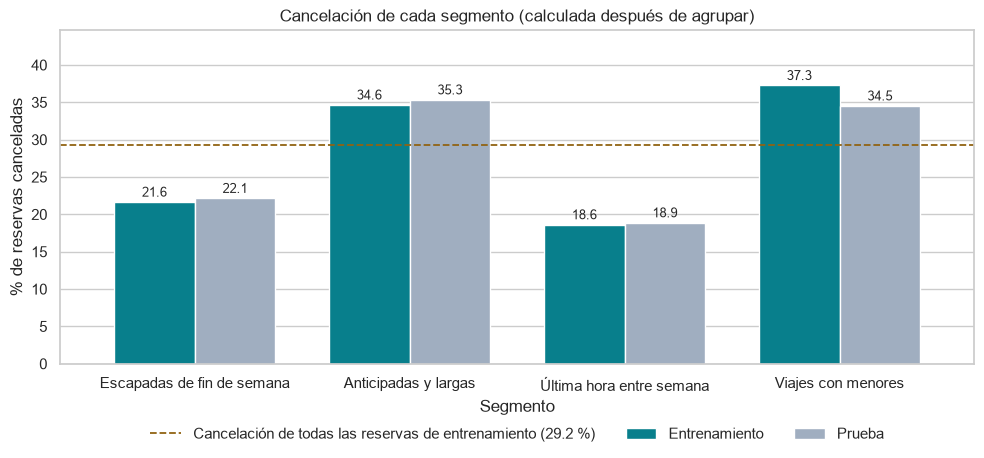

In [24]:
tasa_general = entrenamiento[OBJETIVO].mean() * 100
tasas = pd.DataFrame({
    "Entrenamiento": cancelacion_segmentos[("entrenamiento", "cancelación (%)")],
    "Prueba": cancelacion_segmentos[("prueba", "cancelación (%)")],
}).loc[ORDEN_PERFILES]

fig, ax = plt.subplots(figsize=(10, 4.8))
tasas.plot.bar(ax=ax, color=[COLOR_PRINCIPAL, COLOR_SECUNDARIO], width=0.75, edgecolor="white")
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f", fontsize=9, padding=2)
ax.axhline(tasa_general, color=COLOR_RIESGO, linestyle="--", linewidth=1.3,
           label=f"Cancelación de todas las reservas de entrenamiento ({tasa_general:.1f} %)")
ax.set_ylim(0, tasas.to_numpy().max() * 1.2)
ax.set_title("Cancelación de cada segmento (calculada después de agrupar)")
ax.set_xlabel("Segmento")
ax.set_ylabel("% de reservas canceladas")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=3, frameon=False)
plt.tight_layout()
plt.show()

**¿Qué vemos?**

Los segmentos sí se relacionan con la cancelación, aunque no se armaron con ella. Hay dos perfiles por encima del promedio de 29,2 %, los viajes con menores (37,3 %) y las anticipadas y largas (34,6 %), y dos bastante por debajo, las escapadas de fin de semana (21,6 %) y las de última hora entre semana (18,6 %). En prueba se mantienen esas dos parejas: arriba las anticipadas (35,3 %) y los viajes con menores (34,5 %), y abajo las escapadas (22,1 %) y las de última hora (18,9 %). Entre los dos de arriba el orden se invierte, así que no daríamos por hecho cuál de los dos cancela más.

Cuadra con lo que vimos en el notebook 01: lo que más separa es la anticipación. Los dos perfiles que más cancelan se reservan con meses de anticipación (medianas de 97 y 77 días), y los dos que menos, con dos semanas o menos (14 y 6 días).

Por volumen, el que más pesa son las anticipadas y largas: juntan el 54,0 % de las cancelaciones de entrenamiento (55,3 % en prueba), porque son casi la mitad de las reservas. Los viajes con menores cancelan parecido pero son menos, y aportan el 19,8 %.

La relación no es por azar (chi-cuadrado de 1.833,3, con un valor p tan pequeño que se redondea a 0), pero es débil: la V de Cramér es de 0,170. Ningún segmento es "el que cancela": el que más cancela no llega al 40 % y el que menos pasa del 18 %. Por eso el segmento sirve para decidir dónde poner la atención, pero no reemplaza al modelo supervisado, que mira cada reserva por aparte.

Lo que no permite concluir: que pertenecer a un perfil cause la cancelación. Los perfiles resumen la anticipación, la duración y el tamaño del grupo, y detrás puede haber cosas que el dataset no trae, como las condiciones de cancelación de cada agencia.

Por último, la misma lectura con los grupos de Ward de la sección 3, que solo existen para las 10.000 reservas de la muestra. Sirve para ver si los dos núcleos que encontraron los dos métodos se parecen también en la cancelación.

In [25]:
nombres_ward = {0: "Ward 0 · el resto", 1: "Ward 1 · cortas de fin de semana", 2: "Ward 2 · cortas entre semana"}
muestra = entrenamiento.iloc[indices_muestra]
cancelacion_ward = muestra[OBJETIVO].groupby(pd.Series(segmentos_ward).map(nombres_ward).to_numpy()).agg(
    reservas="size", cancelacion=lambda cancelada: cancelada.mean() * 100
).rename(columns={"cancelacion": "cancelación (%)"})
cancelacion_ward.loc["Toda la muestra"] = [len(muestra), muestra[OBJETIVO].mean() * 100]
cancelacion_ward.round(1)

,reservas,cancelación (%)
Ward 0 · el resto,7681.0,33.6
Ward 1 · cortas de fin de semana,618.0,23.5
Ward 2 · cortas entre semana,1701.0,13.1
Toda la muestra,10000.0,29.5


**¿Qué vemos?**

Los dos núcleos que encontraron los dos métodos también cancelan poco con Ward: las estancias cortas entre semana cancelan 13,1 % y las cortas de fin de semana 23,5 %, contra 29,5 % de toda la muestra. Van en la misma dirección que sus parecidos de K-Means (18,6 % y 21,6 %). Las de entre semana quedan todavía más abajo porque Ward solo apartó las más extremas, las de anticipación mínima. El grupo grande de Ward (33,6 %) junta las anticipadas y los viajes con menores, que son los que más cancelan.

### 4.4 Cierre de la sección

| Segmento | Reservas | Cómo es | Cancelación (entrenamiento / prueba) |
|---|---|---|---|
| Escapadas de fin de semana | 13,4 % | 2 noches, casi todas de fin de semana, 14 días de anticipación | 21,6 % / 22,1 % |
| Anticipadas y largas | 45,5 % | 4 noches, 97 días de anticipación, casi siempre por agencia | 34,6 % / 35,3 % |
| Última hora entre semana | 25,5 % | 1 noche entre semana, 6 días de anticipación, más reservas directas, con empresa y de clientes repetidos | 18,6 % / 18,9 % |
| Viajes con menores | 15,5 % | 3,4 huéspedes, 62,3 % con menores, 77 días de anticipación, 41,9 % llega en julio o agosto | 37,3 % / 34,5 % |

Los perfiles se sostienen con otras muestras (ARI promedio de 0,991) y con reservas que el agrupamiento no vio (ARI de 0,961). Con otras semillas, nueve de diez repiten la misma partición, y la que no lo hace llega a una solución peor, con 0,563 % más de inercia. El segmento más frágil es el de viajes con menores.

Ya con los grupos armados, los segmentos se separan en dos parejas: los que se reservan con tiempo cancelan más que el promedio, y los de poca anticipación, menos. La relación es real pero débil (V de Cramér de 0,170). Las anticipadas y largas juntan más de la mitad de las cancelaciones, así que si el hotel quisiera empezar por un solo perfil, ese es el que más pesa.

Lo que esta sección no permite concluir: que los segmentos sean tipos naturales de reservas, porque la estructura sigue siendo débil (Silhouette de 0,249), ni que el perfil cause la cancelación. Cómo se ven los segmentos en dos dimensiones y qué se pierde al reducir las variables queda para la sección 5.

## 5. Reducción de dimensionalidad de los segmentos

Hasta aquí los segmentos se definieron con las 13 columnas de `Z_entrenamiento`, que incluyen las variables numéricas preparadas y las categorías codificadas. Vamos a ver qué parte de esa estructura se alcanza a ver en dos dimensiones. Usamos PCA para resumir la variación del conjunto y t-SNE para mirar vecindades locales.

Las dos técnicas reciben únicamente las mismas entradas que usó el agrupamiento. Conservamos los cuatro segmentos de K-Means de la sección 4 y añadimos la etiqueta de cancelación solo al dibujar. La regresión logística y la SVM del notebook 03 responden a otra pregunta: qué reservas tienen mayor riesgo individual.

### 5.1 PCA: cuánta varianza vemos en dos ejes

Ajustamos PCA sobre todas las reservas de entrenamiento con la escala de la sección 1.4. Cada componente es una combinación lineal de las columnas y captura parte de su variación. Los componentes se ordenan de mayor a menor varianza explicada. Esta medida se refiere a la matriz preparada, por eso depende de cómo escalamos y codificamos cada variable.

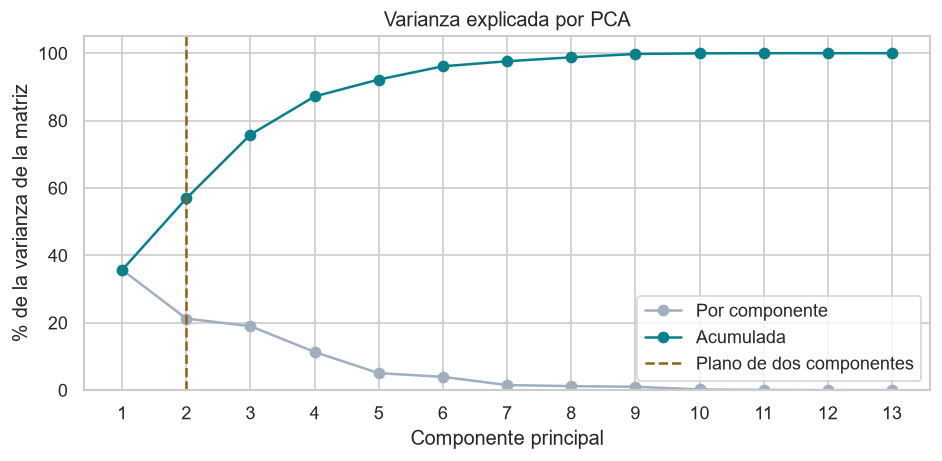

PC1: 35.7 %; PC2: 21.2 %.
Varianza conservada en dos dimensiones: 56.9 %; fuera del plano: 43.1 %.


In [26]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness

DIMENSIONES_GRAFICA = 2
TAMANO_MUESTRA_REDUCCION = 4_000
PERPLEJIDAD_TSNE = 30
ITERACIONES_TSNE = 1_000
VECINOS_DIAGNOSTICO = 15
COLORES_PERFILES = (COLOR_PRINCIPAL, "#5C78A3", "#52616B", "#895E92")

assert OBJETIVO not in X_segmentacion.columns
assert Z_entrenamiento.shape == (len(entrenamiento), len(columnas_z))
assert perfil_entrenamiento.index.equals(entrenamiento.index)

pca = PCA(svd_solver="full").fit(Z_entrenamiento)
varianza_pca = pd.Series(
    100 * pca.explained_variance_ratio_,
    index=pd.Index(range(1, len(columnas_z) + 1), name="componente"),
    name="varianza explicada (%)",
)
varianza_acumulada_pca = varianza_pca.cumsum()
varianza_2d = varianza_acumulada_pca.loc[DIMENSIONES_GRAFICA]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(varianza_pca.index, varianza_pca, marker="o", color=COLOR_SECUNDARIO, label="Por componente")
ax.plot(varianza_pca.index, varianza_acumulada_pca, marker="o", color=COLOR_PRINCIPAL, label="Acumulada")
ax.axvline(DIMENSIONES_GRAFICA, color=COLOR_RIESGO, linestyle="--", label="Plano de dos componentes")
ax.set(title="Varianza explicada por PCA", xlabel="Componente principal", ylabel="% de la varianza de la matriz")
ax.set_xticks(varianza_pca.index)
ax.set_ylim(0, 105)
ax.legend()
plt.tight_layout()
plt.show()

print(f"PC1: {varianza_pca.loc[1]:.1f} %; PC2: {varianza_pca.loc[2]:.1f} %.")
print(f"Varianza conservada en dos dimensiones: {varianza_2d:.1f} %; fuera del plano: {100 - varianza_2d:.1f} %.")

In [27]:
nombres_componentes = [f"PC{i}" for i in range(1, DIMENSIONES_GRAFICA + 1)]
cargas_pca = pd.DataFrame(
    pca.components_[:DIMENSIONES_GRAFICA].T,
    index=pd.Index(columnas_z, name="columna preparada"),
    columns=nombres_componentes,
)
orden_cargas = cargas_pca.abs().max(axis=1).sort_values(ascending=False).index
display(cargas_pca.loc[orden_cargas].round(3))

centros_pca = pd.DataFrame(
    pca.transform(kmeans.cluster_centers_)[:, :DIMENSIONES_GRAFICA],
    index=pd.Index(ORDEN_PERFILES, name="segmento de K-Means"),
    columns=nombres_componentes,
)
display(centros_pca.round(2))

,PC1,PC2
columna preparada,,
proporcion_fin_semana,0.114,0.981
lead_time,0.633,-0.073
total_noches,0.605,0.023
total_huespedes,0.443,-0.172
distribution_channel_TA/TO,0.114,-0.005
con_menores,0.067,-0.037
distribution_channel_Corporate,-0.056,0.009
distribution_channel_Direct,-0.056,-0.005
customer_type_Contract,0.014,-0.001


,PC1,PC2
segmento de K-Means,,
Escapadas de fin de semana,-0.76,1.88
Anticipadas y largas,0.69,-0.02
Última hora entre semana,-1.52,-0.71
Viajes con menores,1.14,-0.39


**¿Qué vemos?** Las cargas de la primera tabla son los coeficientes que usa cada componente para combinar las columnas preparadas. Una carga grande en valor absoluto pesa más en ese eje. El signo indica hacia qué extremo empuja la variable y puede invertirse para todo el eje sin cambiar la geometría. La segunda tabla ubica los centros que ya había encontrado K-Means en el espacio original, proyectados con ese mismo PCA.

Los dos primeros componentes conservan **56,9 %** de la varianza de la matriz preparada. Queda **43,1 %** fuera de la figura. PC1 (35,7 %) combina sobre todo la anticipación, las noches y el número de huéspedes. PC2 (21,2 %) está dominado por la proporción de fin de semana. Esto se ve en la tabla de centros: las escapadas quedan arriba en PC2 (1,88) y las reservas de última hora tienen el menor PC1 (−1,52). El plano muestra bien esos contrastes, pero comprime diferencias en otras columnas, como el tipo de cliente y el canal.

### 5.2 t-SNE: qué reservas quedan cerca

Sacamos una muestra uniforme de 4.000 reservas de entrenamiento, sin reemplazo y con la semilla del equipo. Así acotamos el costo de t-SNE. Usamos las mismas reservas en ambos gráficos para comparar y contrastamos los tamaños de los perfiles con el entrenamiento completo.

t-SNE favorece que las reservas cercanas en la matriz original queden cerca en el plano. Trabajamos con perplejidad 30, que fija una escala de vecindad, e inicialización PCA para que la corrida sea reproducible con la semilla. t-SNE sigue recibiendo las 13 columnas. A diferencia de PCA, sus ejes no tienen cargas interpretables y su resultado depende de la muestra y los parámetros.

In [28]:
generador_reduccion = np.random.default_rng(SEMILLA)
posiciones_reduccion = np.sort(generador_reduccion.choice(
    len(Z_entrenamiento), size=TAMANO_MUESTRA_REDUCCION, replace=False,
))
Z_reduccion = Z_entrenamiento[posiciones_reduccion]

proyecciones = {
    "PCA": pca.transform(Z_reduccion)[:, :DIMENSIONES_GRAFICA],
    "t-SNE": TSNE(
        n_components=DIMENSIONES_GRAFICA,
        perplexity=PERPLEJIDAD_TSNE,
        init="pca",
        learning_rate="auto",
        max_iter=ITERACIONES_TSNE,
        random_state=SEMILLA,
    ).fit_transform(Z_reduccion),
}
assert all(np.isfinite(coordenadas).all() for coordenadas in proyecciones.values())

# Agregamos las etiquetas después de obtener las coordenadas.
perfil_reduccion = perfil_entrenamiento.iloc[posiciones_reduccion].reset_index(drop=True)
cancelacion_reduccion = entrenamiento[OBJETIVO].iloc[posiciones_reduccion].to_numpy()
composicion_reduccion = pd.DataFrame({
    "entrenamiento (%)": perfil_entrenamiento.value_counts(normalize=True) * 100,
    "muestra (%)": perfil_reduccion.value_counts(normalize=True) * 100,
}).reindex(ORDEN_PERFILES)
composicion_reduccion["diferencia (p. p.)"] = (
    composicion_reduccion["muestra (%)"] - composicion_reduccion["entrenamiento (%)"]
)
display(composicion_reduccion.round(2))

vecindad_reduccion = pd.Series({
    metodo: trustworthiness(Z_reduccion, coordenadas, n_neighbors=VECINOS_DIAGNOSTICO)
    for metodo, coordenadas in proyecciones.items()
}, name=f"Conservación local ({VECINOS_DIAGNOSTICO} vecinos)")
display(vecindad_reduccion.round(3).to_frame())

,entrenamiento (%),muestra (%),diferencia (p. p.)
Escapadas de fin de semana,13.41,13.35,-0.06
Anticipadas y largas,45.54,46.12,0.58
Última hora entre semana,25.50,25.90,0.40
Viajes con menores,15.54,14.62,-0.92


,Conservación local (15 vecinos)
PCA,0.914
t-SNE,0.997


Para comparar vecindades usamos `trustworthiness`. Va de 0 a 1 y penaliza que en el plano aparezcan vecinos que estaban lejos en la matriz de entrada. Calculamos la medida sobre las mismas 4.000 filas para ambos métodos. Complementa la varianza de PCA porque contesta una pregunta local y se puede calcular también para t-SNE.

En la muestra, la proporción de cada perfil se aparta menos de un punto porcentual de la del entrenamiento. Eso permite ver los cuatro perfiles con tamaños parecidos a los originales. En las mismas filas y con 15 vecinos, t-SNE obtiene **0,997** y PCA **0,914**. Con esta configuración, t-SNE introduce menos vecinos lejanos en el plano. La medida no dice si se conservaron las distancias globales o si los grupos están mejor definidos.

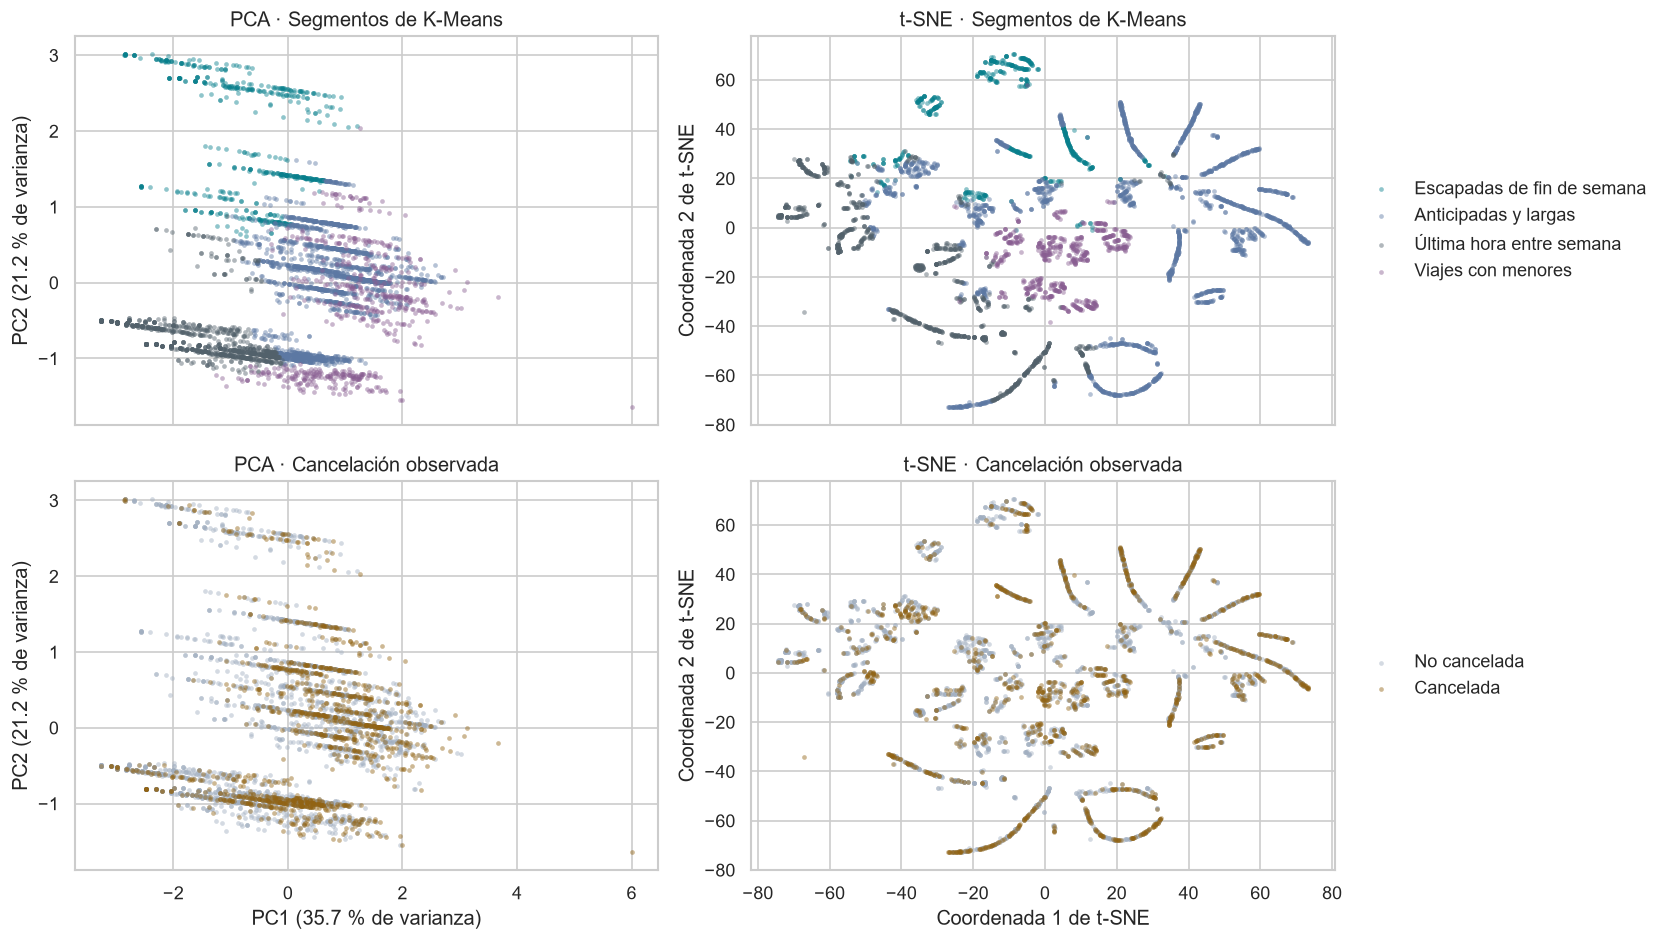

In [29]:
def dibujar_reduccion(ax, coordenadas, grupos, etiquetas, colores):
    """Dibuja las coordenadas con un color por etiqueta, sin volver a ajustar la proyección."""
    for grupo, etiqueta, color in zip(grupos, etiquetas, colores):
        puntos = coordenadas[grupo]
        ax.scatter(puntos[:, 0], puntos[:, 1], s=8, alpha=0.45, linewidths=0, color=color, label=etiqueta)


mascaras_perfiles = [perfil_reduccion.eq(nombre).to_numpy() for nombre in ORDEN_PERFILES]
mascaras_cancelacion = [cancelacion_reduccion == valor for valor in (0, 1)]

fig, ejes = plt.subplots(2, 2, figsize=(14, 8), sharex="col", sharey="col")
for columna, (metodo, coordenadas) in enumerate(proyecciones.items()):
    ax_perfiles, ax_cancelacion = ejes[:, columna]
    dibujar_reduccion(ax_perfiles, coordenadas, mascaras_perfiles, ORDEN_PERFILES, COLORES_PERFILES)
    dibujar_reduccion(ax_cancelacion, coordenadas, mascaras_cancelacion,
                      ["No cancelada", "Cancelada"], [COLOR_SECUNDARIO, COLOR_RIESGO])

    ax_perfiles.set_title(f"{metodo} · Segmentos de K-Means")
    ax_cancelacion.set_title(f"{metodo} · Cancelación observada")
    if metodo == "PCA":
        ax_cancelacion.set_xlabel(f"PC1 ({varianza_pca.loc[1]:.1f} % de varianza)")
        etiqueta_y = f"PC2 ({varianza_pca.loc[2]:.1f} % de varianza)"
    else:
        ax_cancelacion.set_xlabel("Coordenada 1 de t-SNE")
        etiqueta_y = "Coordenada 2 de t-SNE"
    ax_perfiles.set_ylabel(etiqueta_y)
    ax_cancelacion.set_ylabel(etiqueta_y)

for ax in ejes[:, 1]:
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.tight_layout()
plt.show()

### 5.3 Qué nos aporta la reducción

En PCA, las escapadas de fin de semana aparecen arriba y las reservas de última hora tienden a quedar abajo a la izquierda. Las anticipadas y largas se superponen en parte con los viajes con menores. t-SNE conserva mejor las vecindades de la muestra y dibuja varias islas del mismo perfil. El tamaño y la distancia entre esas islas dependen de la proyección. Para valorar la separación de los cuatro segmentos seguimos usando el espacio original, donde K-Means obtuvo un Silhouette de 0,249 y el acuerdo con Ward fue bajo.

En ambos planos vemos reservas canceladas y no canceladas en las mismas zonas. El color ayuda a localizar la mezcla. Para comparar tasas y volumen volvemos a la sección 4, donde las anticipadas y largas concentraron el 54,0 % de las cancelaciones de entrenamiento. Eso permite priorizar un perfil sin asumir que pertenecer a él causa una cancelación.

PCA resume los contrastes globales de la matriz con ejes interpretables. t-SNE añade una vista de vecindades locales. Las dos figuras complementan los perfiles de K-Means. En el notebook 05 podremos contrastar esa información de grupo con el riesgo individual que estiman la SVM y la regresión logística.